# BÁO CÁO CUỐI KỲ — ADY201m
## Phân loại nhãn tiền tiểu đường/tiểu đường trong khảo sát BRFSS2015 ở người từ 60 tuổi trở lên
**Nhóm 6 — AI2104**

| Thành viên | Mã sinh viên |
|---|---|
| Trần Tuấn Hiệp | HE211144 |
| Nguyễn Thế Hải | HE211655 |
| Trần Công Du | HE211007 |

Nhóm phân tích dữ liệu khảo sát bằng SQL và Python, sau đó so sánh hai bộ đặc trưng bằng XGBoost trên cùng năm fold. Nhóm dò siêu tham số XGBoost bằng RandomizedSearchCV và chọn ngưỡng bằng dự đoán ngoài fold trên Train. Trên Test, nhóm báo cáo F1, Precision, Recall và ROC-AUC, phân tích lỗi và diễn giải mô hình. Nhãn 1 gộp tiền tiểu đường và tiểu đường tự khai.

**Cách đọc:** Phần I–III trình bày vấn đề, nguồn dữ liệu và tiền xử lý. Phần IV trình bày phân tích khám phá, hai bộ đặc trưng và kiểm tra VIF. Phần V chia Train/Test. Phần VI so sánh đặc trưng, dò siêu tham số và chọn ngưỡng. Phần VII đánh giá và diễn giải XGBoost trên Test. Phần VIII tổng hợp kết quả, giới hạn và hướng phát triển.

# I. Vấn đề và phương pháp nghiên cứu


#### BUSINESS CONTEXT & PROJECT JUSTIFICATION

**Bối cảnh:** Nhóm hướng đến tình huống người từ 60 tuổi trở lên muốn được đánh giá ban đầu về tình trạng tiền tiểu đường/tiểu đường trong thời gian chờ kết quả xét nghiệm. Nhóm tìm hiểu khả năng sử dụng học máy để khai thác các thông tin sức khỏe, hành vi và nhân khẩu học mà người tham gia cung cấp trong khảo sát. Qua nghiên cứu này, nhóm muốn đánh giá tiềm năng hỗ trợ nhân viên y tế tham khảo thông tin trước khi đưa ra quyết định chuyên môn.

**Vấn đề nghiên cứu:** Nhóm dùng XGBoost để phân loại nhãn gộp tiền tiểu đường/tiểu đường từ các đặc điểm khảo sát của người từ 60 tuổi trở lên. Nhóm so sánh hai bộ đặc trưng trên cùng năm fold. Trên Test, nhóm xem xét khả năng nhận diện lớp dương và các lỗi báo nhầm, bỏ sót của XGBoost.

**Lý do chọn nhóm tuổi từ 60 trở lên:** Nhóm lựa chọn người từ 60 tuổi trở lên vì nguy cơ mắc tiểu đường tăng theo tuổi, nên đây là nhóm có nguy cơ cao hơn và cần được hỗ trợ đánh giá ban đầu [nguồn nhóm bổ sung]. Nhóm giới hạn phạm vi tuổi để tìm hiểu khả năng phân loại nhãn khảo sát trong nhóm đối tượng này. Nhóm không diễn giải mối liên hệ với tuổi như quan hệ nhân quả và không suy ra tỷ lệ bệnh trong dân số từ mẫu khảo sát.

**Đối tượng sử dụng và quyết định hỗ trợ:** Nhóm xác định người từ 60 tuổi trở lên là đối tượng hưởng lợi dự kiến và nhân viên y tế là người sử dụng kết quả tham khảo. Trong phạm vi đề tài, nhóm đánh giá mô hình trên dữ liệu khảo sát. Nhân viên y tế giữ quyền quyết định về xét nghiệm, chẩn đoán và chăm sóc người bệnh.

**Phạm vi và giới hạn:** Nhóm giữ nhãn gộp hiện tại: lớp 1 gồm tiền tiểu đường và tiểu đường tự khai (DIABETE3=1 hoặc 4); lớp 0 gồm người trả lời không mắc tiểu đường (DIABETE3=3). Nhóm loại hồ sơ chỉ tiểu đường khi mang thai (DIABETE3=2). Nhóm đánh giá khả năng phân loại nhãn khảo sát trong mẫu sau làm sạch; nhóm không sử dụng kết quả để khẳng định khả năng dự đoán phát bệnh trong tương lai hoặc quan hệ nhân quả.


#### CORE RESEARCH QUESTIONS

1. **Trong mẫu người từ 60 tuổi trở lên, nhóm quan sát thấy những đặc điểm sức khỏe, hành vi và nhân khẩu học nào có liên quan đến nhãn gộp tiền tiểu đường/tiểu đường?**

2. **XGBoost đạt F1, Precision, Recall và ROC-AUC ở mức nào khi phân loại nhãn gộp từ các đặc điểm khảo sát?**

3. **Việc chọn ngưỡng phân loại ảnh hưởng thế nào đến sự đánh đổi giữa Precision và Recall của lớp 1?**

Nhóm sử dụng SQL để kiểm tra và chuẩn bị dữ liệu; nhóm sử dụng pandas/NumPy để phân tích các câu hỏi nghiên cứu và tổng hợp kết quả mô hình trong các phần sau.


#### DATA SCIENCE PROBLEM FORMULATION

- **Loại bài toán:** Nhóm thực hiện bài toán học có giám sát, phân loại nhị phân trong phạm vi nghiên cứu học thuật.
- **Đơn vị phân tích:** Nhóm phân tích từng bản ghi khảo sát của người từ 60 tuổi trở lên sau khi áp dụng các điều kiện chọn mẫu và làm sạch dữ liệu.
- **Biến mục tiêu:** Nhóm sử dụng `Diabetes_binary`, gán lớp 0 cho `DIABETE3=3` và lớp 1 cho `DIABETE3=1` hoặc `4`. Nhóm loại hồ sơ chỉ tiểu đường khi mang thai (`DIABETE3=2`) và trình bày cách xử lý nhãn thiếu hoặc mã phản hồi không hợp lệ ở phần tiền xử lý.
- **Đầu vào:** Nhóm sử dụng 20 đặc điểm sức khỏe, hành vi và nhân khẩu học làm bộ ứng viên ban đầu. Nhóm sẽ trình bày các bộ đặc trưng dùng trong thử nghiệm tại phần lựa chọn đặc trưng.
- **Đầu ra:** Với mỗi bản ghi, nhóm sử dụng mô hình để phân loại vào lớp 0 hoặc lớp 1 theo định nghĩa nhãn gộp.
- **Đánh giá:** Nhóm dùng F1 lớp 1 trên cùng năm fold của Train để so sánh hai bộ đặc trưng bằng XGBoost. Nhóm dò siêu tham số XGBoost bằng RandomizedSearchCV và chọn ngưỡng theo F1 ngoài fold. Trên Test, nhóm báo cáo F1, Precision, Recall và ROC-AUC, rồi dùng ma trận nhầm lẫn để phân tích báo nhầm và bỏ sót.
- **Phạm vi diễn giải:** Nhóm đánh giá khả năng phân loại nhãn tự khai trong mẫu khảo sát sau làm sạch. Nhóm chưa kiểm chứng khả năng ứng dụng tại bệnh viện hoặc dự báo phát bệnh trong tương lai.


# II. Nguồn dữ liệu và khám phá ban đầu

### DATA SOURCE & COLLECTION METHOD

Nhóm sử dụng `data.csv` làm đầu vào của báo cáo. Nhóm tạo tệp này từ `data_đầu_vào/2015.csv` bằng cách chọn `_AGEG5YR` mã 9–13, gồm người từ 60 tuổi trở lên. Nhóm giữ 202,412 hồ sơ và 330 cột nguồn, giữ nguyên thứ tự hồ sơ, giá trị thiếu và mã khảo sát. Nhóm chưa làm sạch, loại nhãn hoặc xóa hồ sơ trùng khi tạo tệp.

Nhóm sử dụng dữ liệu khảo sát BRFSS2015 do CDC công bố và tham khảo bộ biến của Alex Teboul để chọn 20 đặc trưng ứng viên cùng một biến mục tiêu. Nhóm sẽ loại `DIABETE3=2`, xử lý mã phản hồi và tạo nhãn gộp tiền tiểu đường/tiểu đường trong phần tiền xử lý.

Nhóm đọc trực tiếp `data.csv` bằng pandas khi chạy báo cáo. Nhóm không cần giải nén ZIP hoặc đọc XPT. Nhóm tính số hồ sơ trước và sau làm sạch từ đầu vào đã chọn tuổi này.

**Nguồn:** [CDC BRFSS2015](https://www.cdc.gov/brfss/annual_data/annual_2015.html), [codebook, trang 112](https://www.cdc.gov/brfss/annual_data/2015/pdf/CODEBOOK15_LLCP.pdf), [bộ biến tham khảo](https://www.kaggle.com/datasets/alexteboul/diabetes-health-indicators-dataset).


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3

# 1. Đọc tệp khảo sát BRFSS 2015
df_raw = pd.read_csv('data.csv', float_precision='round_trip')
print(f"Kích thước tệp dữ liệu thô: {df_raw.shape[0]:,} dòng × {df_raw.shape[1]} cột")

# 2. Danh sách 20 cột đặc trưng ứng viên và 1 cột nhãn mục tiêu
SOURCE_COLS = [
    'DIABETE3', '_RFHYPE5', 'TOLDHI2', '_CHOLCHK', '_BMI5', 'SMOKE100', 'CVDSTRK3', '_MICHD',
    '_TOTINDA', '_FRTLT1', '_VEGLT1', '_RFDRHV5', 'HLTHPLN1', 'MEDCOST', 'GENHLTH', 'MENTHLTH',
    'PHYSHLTH', 'DIFFWALK', 'SEX', '_AGEG5YR', 'EDUCA'
]

# 3. Lọc phạm vi nghiên cứu: Người từ 60 tuổi trở lên (_AGEG5YR từ 9 đến 13) và loại tiểu đường thai kỳ (DIABETE3 != 2)
df_scope = df_raw[df_raw['_AGEG5YR'].isin([9, 10, 11, 12, 13]) & (df_raw['DIABETE3'] != 2)][SOURCE_COLS].copy()
print(f"Số hồ sơ đúng phạm vi nghiên cứu (≥60 tuổi): {len(df_scope):,} dòng")


Kích thước tệp dữ liệu thô: 202,412 dòng × 330 cột
Số hồ sơ đúng phạm vi nghiên cứu (≥60 tuổi): 201,596 dòng


In [2]:
# Bảng 1: Hiển thị 5 dòng đầu tiên của dữ liệu thô
display(df_raw.head())


,_STATE,FMONTH,IDATE,IMONTH,IDAY,IYEAR,DISPCODE,SEQNO,_PSU,CTELENUM,PVTRESD1,COLGHOUS,STATERES,CELLFON3,LADULT,NUMADULT,NUMMEN,NUMWOMEN,CTELNUM1,CELLFON2,CADULT,PVTRESD2,CCLGHOUS,CSTATE,LANDLINE,HHADULT,GENHLTH,PHYSHLTH,MENTHLTH,POORHLTH,HLTHPLN1,PERSDOC2,MEDCOST,CHECKUP1,BPHIGH4,BPMEDS,BLOODCHO,CHOLCHK,TOLDHI2,CVDINFR4,...,_VEG23,_FRUITEX,_VEGETEX,_TOTINDA,METVL11_,METVL21_,MAXVO2_,FC60_,ACTIN11_,ACTIN21_,PADUR1_,PADUR2_,PAFREQ1_,PAFREQ2_,_MINAC11,_MINAC21,STRFREQ_,PAMISS1_,PAMIN11_,PAMIN21_,PA1MIN_,PAVIG11_,PAVIG21_,PA1VIGM_,_PACAT1,_PAINDX1,_PA150R2,_PA300R2,_PA30021,_PASTRNG,_PAREC1,_PASTAE1,_LMTACT1,_LMTWRK1,_LMTSCL1,_RFSEAT2,_RFSEAT3,_FLSHOT6,_PNEUMO2,_AIDTST3
0,1.0,1.0,1292015,1,29,2015,1200.0,2.015000e+09,2.015000e+09,1.0,1.0,NaN,1.0,2.0,NaN,3.0,1.000000e+00,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0,15.0,18.0,10.0,1.0,1.0,2.0,1.0,1.0,1.0,1.0,1.0,1.0,2.0,...,1.0,5.397605e-79,5.397605e-79,2.0,NaN,NaN,2469.0,423.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.397605e-79,5.397605e-79,NaN,NaN,NaN,NaN,NaN,NaN,4.0,2.0,3.0,3.0,2.0,2.0,4.0,2.0,1.0,1.0,1.0,1.0,1.0,NaN,NaN,1.0
1,1.0,1.0,2012015,2,1,2015,1200.0,2.015000e+09,2.015000e+09,1.0,1.0,NaN,1.0,2.0,NaN,2.0,1.000000e+00,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.0,15.0,88.0,88.0,1.0,2.0,2.0,1.0,3.0,NaN,1.0,1.0,1.0,7.0,...,1.0,1.000000e+00,1.000000e+00,9.0,NaN,NaN,2173.0,373.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9.000000e+00,NaN,NaN,NaN,NaN,NaN,NaN,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,NaN
2,1.0,1.0,1142015,1,14,2015,1100.0,2.015000e+09,2.015000e+09,1.0,1.0,NaN,1.0,2.0,NaN,3.0,1.000000e+00,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0,30.0,30.0,30.0,1.0,2.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,2.0,...,1.0,5.397605e-79,5.397605e-79,2.0,NaN,NaN,2469.0,423.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.397605e-79,5.397605e-79,NaN,NaN,NaN,NaN,NaN,NaN,4.0,2.0,3.0,3.0,2.0,2.0,4.0,2.0,1.0,1.0,1.0,1.0,1.0,NaN,NaN,9.0
3,1.0,1.0,1142015,1,14,2015,1100.0,2.015000e+09,2.015000e+09,1.0,1.0,NaN,1.0,2.0,NaN,2.0,1.000000e+00,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0,20.0,88.0,30.0,1.0,1.0,2.0,1.0,3.0,NaN,1.0,1.0,2.0,2.0,...,1.0,1.000000e+00,5.397605e-79,2.0,NaN,NaN,2543.0,436.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.397605e-79,5.397605e-79,NaN,NaN,NaN,NaN,NaN,NaN,4.0,2.0,3.0,3.0,2.0,2.0,4.0,2.0,1.0,1.0,1.0,1.0,1.0,NaN,NaN,1.0
4,1.0,1.0,1142015,1,14,2015,1100.0,2.015000e+09,2.015000e+09,1.0,1.0,NaN,1.0,2.0,NaN,1.0,5.397605e-79,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,88.0,88.0,NaN,1.0,1.0,2.0,1.0,1.0,1.0,1.0,1.0,2.0,2.0,...,1.0,5.397605e-79,5.397605e-79,1.0,50.0,33.0,2099.0,360.0,2.0,1.0,60.0,30.0,1000.0,7000.0,60.0,210.0,5.397605e-79,5.397605e-79,120.0,210.0,330.0,60.0,5.397605e-79,60.0,1.0,1.0,1.0,1.0,1.0,2.0,2.0,2.0,1.0,2.0,3.0,1.0,1.0,1.0,1.0,2.0


In [3]:
# Bảng 2: Thông tin tổng quan tệp khảo sát BRFSS 2015
df_file_info = pd.DataFrame([{
    "Tệp": "data.csv (BRFSS 2015)",
    "Số hồ sơ": f"{len(df_raw):,}",
    "Số cột nguồn": df_raw.shape[1],
    "Số biến ứng viên và nhãn": len(SOURCE_COLS),
    "Độ tuổi nghiên cứu": "Từ 60 tuổi trở lên (mã 9–13)"
}])
display(df_file_info)


,Tệp,Số hồ sơ,Số cột nguồn,Số biến ứng viên và nhãn,Độ tuổi nghiên cứu
0,data.csv (BRFSS 2015),"202,412",330,21,Từ 60 tuổi trở lên (mã 9–13)


In [4]:
# Bảng 3: Cơ cấu phân bố người cao tuổi theo nhóm tuổi trong dữ liệu thô
# Ánh xạ mã nhóm tuổi BRFSS sang khoảng tuổi thực tế
age_map = {9: '60–64 tuổi', 10: '65–69 tuổi', 11: '70–74 tuổi', 12: '75–79 tuổi', 13: 'Từ 80 tuổi trở lên'}

age_thô = df_scope['_AGEG5YR'].value_counts().sort_index().rename(index=age_map).reset_index()
age_thô.columns = ['Nhóm tuổi', 'Số hồ sơ']
age_thô['Tỷ lệ (%)'] = (age_thô['Số hồ sơ'] / len(df_scope) * 100).round(2)
display(age_thô)


,Nhóm tuổi,Số hồ sơ,Tỷ lệ (%)
0,60–64 tuổi,49566,24.59
1,65–69 tuổi,49075,24.34
2,70–74 tuổi,38226,18.96
3,75–79 tuổi,28128,13.95
4,Từ 80 tuổi trở lên,36601,18.16


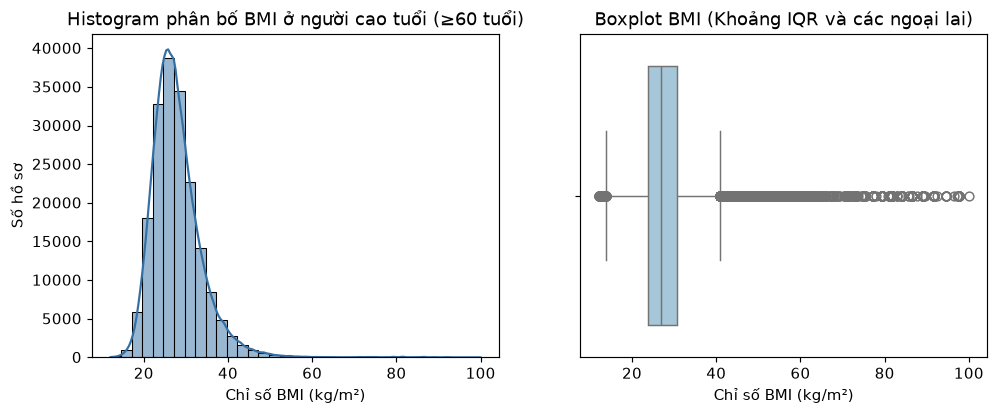

In [5]:
# Biểu đồ 1: Phân bố BMI thô trước làm sạch và thống kê khoảng IQR
# Chỉ số BMI trong BRFSS được lưu dưới dạng _BMI5 nhân 100
bmi_raw = (df_scope['_BMI5'].dropna() / 100.0).round(2)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(bmi_raw, bins=35, color='#3470a3', kde=True, ax=ax1)
ax1.set_title("Histogram phân bố BMI ở người cao tuổi (≥60 tuổi)")
ax1.set_xlabel("Chỉ số BMI (kg/m²)")
ax1.set_ylabel("Số hồ sơ")

sns.boxplot(x=bmi_raw, color='#9ecae1', ax=ax2)
ax2.set_title("Boxplot BMI (Khoảng IQR và các ngoại lai)")
ax2.set_xlabel("Chỉ số BMI (kg/m²)")
plt.show()


In [6]:
# Bảng 4: Chất lượng 20 biến ứng viên và nhãn mục tiêu trước làm sạch
# Đếm số ô khuyết (NaN) và các mã khảo sát không biết/từ chối (7, 9, 77, 99)
records_qual = []
for col in SOURCE_COLS:
    n_nan = df_scope[col].isna().sum()
    n_spec = df_scope[col].isin([7, 9, 77, 99, 9999]).sum()
    records_qual.append({
        'Biến': col,
        'Số ô NaN': n_nan,
        'Tỷ lệ NaN (%)': round(n_nan / len(df_scope) * 100, 2),
        'Số mã đặc biệt': n_spec,
        'Tỷ lệ mã đặc biệt (%)': round(n_spec / len(df_scope) * 100, 2)
    })
df_quality = pd.DataFrame(records_qual).sort_values('Số ô NaN', ascending=False).reset_index(drop=True)
display(df_quality)


,Biến,Số ô NaN,Tỷ lệ NaN (%),Số mã đặc biệt,Tỷ lệ mã đặc biệt (%)
0,_BMI5,13657,6.77,0,0.00
1,TOLDHI2,9412,4.67,2154,1.07
2,SMOKE100,5732,2.84,1495,0.74
3,DIFFWALK,4962,2.46,1272,0.63
4,_MICHD,2532,1.26,0,0.00
5,DIABETE3,5,0.00,335,0.17
6,PHYSHLTH,1,0.00,9942,4.93
7,GENHLTH,1,0.00,741,0.37
8,MEDCOST,1,0.00,586,0.29
9,_CHOLCHK,0,0.00,5755,2.85


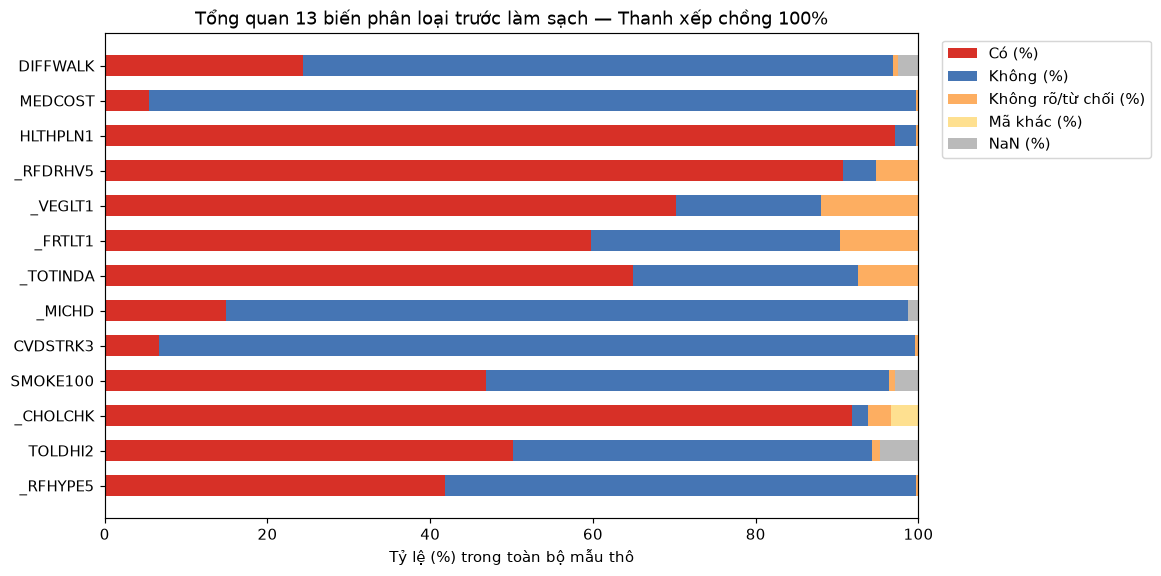

In [7]:
# Biểu đồ 2: Phân bố 13 biến phân loại trước làm sạch — Thanh xếp chồng 100%
binary_candidates = ['_RFHYPE5', 'TOLDHI2', '_CHOLCHK', 'SMOKE100', 'CVDSTRK3', '_MICHD',
                     '_TOTINDA', '_FRTLT1', '_VEGLT1', '_RFDRHV5', 'HLTHPLN1', 'MEDCOST', 'DIFFWALK']
cat_rates = []
for c in binary_candidates:
    total = len(df_scope)
    nan_cnt = df_scope[c].isna().sum()
    spec_cnt = df_scope[c].isin([7, 9, 77, 99]).sum()
    yes_cnt = (df_scope[c] == 1).sum()
    no_cnt = (df_scope[c] == 2).sum()
    other_cnt = total - nan_cnt - spec_cnt - yes_cnt - no_cnt
    cat_rates.append({
        "Biến": c,
        "Có (%)": round(yes_cnt / total * 100, 2),
        "Không (%)": round(no_cnt / total * 100, 2),
        "Không rõ/từ chối (%)": round(spec_cnt / total * 100, 2),
        "Mã khác (%)": round(other_cnt / total * 100, 2),
        "NaN (%)": round(nan_cnt / total * 100, 2)
    })
df_cat_summary = pd.DataFrame(cat_rates)

fig, ax = plt.subplots(figsize=(10, 6))
bottom = np.zeros(len(df_cat_summary))
colors = [("Có (%)", "#d73027"), ("Không (%)", "#4575b4"), ("Không rõ/từ chối (%)", "#fdae61"), ("Mã khác (%)", "#fee090"), ("NaN (%)", "#bababa")]
for col, color in colors:
    ax.barh(df_cat_summary['Biến'], df_cat_summary[col], left=bottom, label=col, color=color, height=0.6)
    bottom += df_cat_summary[col]
ax.set_xlim(0, 100)
ax.set_xlabel("Tỷ lệ (%) trong toàn bộ mẫu thô")
ax.set_title("Tổng quan 13 biến phân loại trước làm sạch — Thanh xếp chồng 100%")
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.show()


In [8]:
# Bảng 5: Tỷ lệ chi tiết (%) của các biến phân loại trong dữ liệu thô
display(df_cat_summary)


,Biến,Có (%),Không (%),Không rõ/từ chối (%),Mã khác (%),NaN (%)
0,_RFHYPE5,41.80,57.86,0.34,0.00,0.00
1,TOLDHI2,50.22,44.04,1.07,0.00,4.67
2,_CHOLCHK,91.80,1.96,2.85,3.39,0.00
3,SMOKE100,46.91,49.51,0.74,0.00,2.84
4,CVDSTRK3,6.73,92.89,0.38,0.00,0.00
5,_MICHD,14.94,83.80,0.00,0.00,1.26
6,_TOTINDA,64.95,27.64,7.41,0.00,0.00
7,_FRTLT1,59.80,30.60,9.60,0.00,0.00
8,_VEGLT1,70.15,17.91,11.94,0.00,0.00
9,_RFDRHV5,90.67,4.11,5.21,0.00,0.00


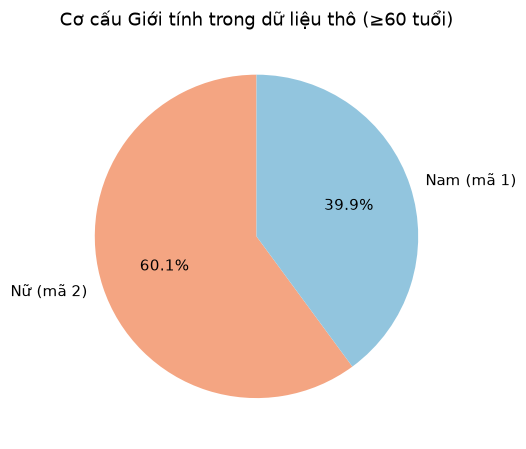

In [9]:
# Biểu đồ 3: Cơ cấu Giới tính trong dữ liệu thô (≥60 tuổi)
fig, ax = plt.subplots(figsize=(5, 5))
sex_counts = df_scope['SEX'].value_counts()
ax.pie(sex_counts, labels=['Nữ (mã 2)', 'Nam (mã 1)'], autopct='%1.1f%%', colors=['#f4a582', '#92c5de'], startangle=90)
ax.set_title("Cơ cấu Giới tính trong dữ liệu thô (≥60 tuổi)")
plt.show()


In [10]:
# Bảng 6: Cơ cấu câu trả lời nhãn mục tiêu DIABETE3 trước làm sạch
diab_map = {1: 'Có tiểu đường', 3: 'Không tiểu đường', 4: 'Tiền tiểu đường / Giáp biên', 7: 'Không biết', 9: 'Từ chối'}
diab_counts = df_scope['DIABETE3'].value_counts().rename(index=diab_map).reset_index()
diab_counts.columns = ['Phản hồi khảo sát', 'Số hồ sơ']
diab_counts['Tỷ lệ (%)'] = (diab_counts['Số hồ sơ'] / len(df_scope) * 100).round(2)
display(diab_counts)


,Phản hồi khảo sát,Số hồ sơ,Tỷ lệ (%)
0,Không tiểu đường,156784,77.77
1,Có tiểu đường,39686,19.69
2,Tiền tiểu đường / Giáp biên,4786,2.37
3,Không biết,273,0.14
4,Từ chối,62,0.03


### Nhận xét từ bước khám phá

Nhóm đặt nhận xét theo số liệu cạnh bảng chất lượng và các biểu đồ. Nhóm dùng năm nhóm tuổi mã 9–13, giữ nhãn DIABETE3 gốc và phân biệt NaN với mã không biết/từ chối. Nhóm giữ BMI dạng số thập phân sau khi chia 100. Nhóm sẽ quyết định cách xử lý giá trị thiếu, hồ sơ trùng và ngoại lệ ở phần tiền xử lý.

Nhóm mô tả tỷ lệ trong mẫu, chưa áp dụng trọng số khảo sát hoặc suy luận quan hệ nhân quả.


#### DATA DICTIONARY

Nhóm lựa chọn 20 đặc trưng ứng viên và một biến mục tiêu từ 330 cột trong `data.csv` (sau khi loại bỏ hoàn toàn biến `Income` nhằm tránh thiên lệch do tỷ lệ từ chối trả lời cao và bảo toàn cỡ mẫu lớn). Bảng dưới đây trình bày tên biến nguồn, ý nghĩa, loại biến và cách biểu diễn dự kiến trong phân tích. Nhóm sẽ trình bày quy tắc xử lý giá trị thiếu và mã phản hồi không hợp lệ tại phần tiền xử lý.

In [11]:
# Bảng 7: Từ điển 20 biến đặc trưng đầu vào và nhãn mục tiêu
# Định nghĩa danh sách các biến phân tích chuẩn hóa
FEATURES = [
    'HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke',
    'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies',
    'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth',
    'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education'
]
TARGET = 'Diabetes_binary'

dict_df = pd.DataFrame({
    "Tên cột nguồn": SOURCE_COLS,
    "Tên dùng trong phân tích": [TARGET] + FEATURES,
    "Ý nghĩa lâm sàng": [
        "Tình trạng mắc đái tháo đường tự khai (Biến mục tiêu)",
        "Tiền sử được chẩn đoán tăng huyết áp",
        "Tiền sử được chẩn đoán cholesterol cao",
        "Đã xét nghiệm kiểm tra cholesterol trong vòng 5 năm qua",
        "Chỉ số khối cơ thể (BMI = Cân nặng kg / Chiều cao m²)",
        "Người từng hút ít nhất 100 điếu thuốc lá trong đời",
        "Tiền sử từng bị đột quỵ",
        "Tiền sử bệnh mạch vành hoặc nhồi máu cơ tim",
        "Có tham gia hoạt động thể lực hoặc tập thể dục ngoài giờ làm",
        "Tiêu thụ trái cây ít nhất 1 lần mỗi ngày",
        "Tiêu thụ rau xanh ít nhất 1 lần mỗi ngày",
        "Uống rượu bia mức độ nặng (Nam >14 ly/tuần, Nữ >7 ly/tuần)",
        "Có bất kỳ loại bảo hiểm y tế hoặc chương trình chăm sóc sức khỏe nào",
        "Không thể đi khám bác sĩ trong 12 tháng qua do chi phí",
        "Tự đánh giá tình trạng sức khỏe tổng quát (1: Rất tốt đến 5: Kém)",
        "Số ngày sức khỏe tinh thần không tốt trong 30 ngày qua (0–30 ngày)",
        "Số ngày sức khỏe thể chất không tốt trong 30 ngày qua (0–30 ngày)",
        "Khó khăn nghiêm trọng khi đi bộ hoặc leo cầu thang",
        "Giới tính sinh học (0: Nữ, 1: Nam)",
        "Nhóm tuổi 5 năm từ 60 tuổi trở lên (9: 60–64 tuổi đến 13: ≥80 tuổi)",
        "Trình độ học vấn cao nhất đạt được (1: Chưa tốt nghiệp đến 6: Đại học)"
    ],
    "Loại biến": [
        "Nhị phân (0/1)", "Nhị phân (0/1)", "Nhị phân (0/1)", "Nhị phân (0/1)",
        "Số liên tục (kg/m²)", "Nhị phân (0/1)", "Nhị phân (0/1)", "Nhị phân (0/1)",
        "Nhị phân (0/1)", "Nhị phân (0/1)", "Nhị phân (0/1)", "Nhị phân (0/1)",
        "Nhị phân (0/1)", "Nhị phân (0/1)", "Thứ bậc (1–5)", "Số nguyên (0–30)",
        "Số nguyên (0–30)", "Nhị phân (0/1)", "Nhị phân (0/1)", "Thứ bậc (9–13)", "Thứ bậc (1–6)"
    ],
    "Mã trong nguồn BRFSS": [
        "1: Có, 2: Thai kỳ, 3: Không, 4: Tiền TĐ", "1: Không, 2: Có, 9: Không rõ",
        "1: Có, 2: Không, 7/9: Không rõ", "1: ≤5 năm, 2: >5 năm, 3: Chưa, 9: Không rõ",
        "BMI × 100 (Ví dụ 2450 = 24.50)", "1: Có, 2: Không, 7/9: Không rõ",
        "1: Có, 2: Không, 7/9: Không rõ", "1: Có, 2: Không",
        "1: Có, 2: Không, 9: Không rõ", "1: ≥1 lần/ngày, 2: Chưa, 9: Không rõ",
        "1: ≥1 lần/ngày, 2: Chưa, 9: Không rõ", "1: Không, 2: Có, 9: Không rõ",
        "1: Có, 2: Không, 7/9: Không rõ", "1: Có, 2: Không, 7/9: Không rõ",
        "1: Rất tốt đến 5: Kém, 7/9: Không rõ", "1–30: Số ngày, 88: 0 ngày, 77/99: Không rõ",
        "1–30: Số ngày, 88: 0 ngày, 77/99: Không rõ", "1: Có, 2: Không, 7/9: Không rõ",
        "1: Nam, 2: Nữ", "9: 60–64 đến 13: ≥80 tuổi", "1: Mẫu giáo đến 6: ĐH, 9: Từ chối"
    ],
    "Mã sau chuẩn hóa": [
        "3 → 0; 1, 4 → 1", "1 → 0; 2 → 1", "1 → 1; 2 → 0", "1 → 1; 2, 3 → 0",
        "_BMI5 / 100.0", "1 → 1; 2 → 0", "1 → 1; 2 → 0", "1 → 1; 2 → 0",
        "1 → 1; 2 → 0", "1 → 1; 2 → 0", "1 → 1; 2 → 0", "1 → 0; 2 → 1",
        "1 → 1; 2 → 0", "1 → 1; 2 → 0", "Giữ nguyên 1–5", "88 → 0; 1–30 giữ nguyên",
        "88 → 0; 1–30 giữ nguyên", "1 → 1; 2 → 0", "2 → 0 (Nữ); 1 → 1 (Nam)",
        "Giữ nguyên mã 9–13", "Giữ nguyên mã 1–6"
    ]
})
display(dict_df)


,Tên cột nguồn,Tên dùng trong phân tích,Ý nghĩa lâm sàng,Loại biến,Mã trong nguồn BRFSS,Mã sau chuẩn hóa
0,DIABETE3,Diabetes_binary,Tình trạng mắc đái tháo đường tự khai (Biến mụ...,Nhị phân (0/1),"1: Có, 2: Thai kỳ, 3: Không, 4: Tiền TĐ","3 → 0; 1, 4 → 1"
1,_RFHYPE5,HighBP,Tiền sử được chẩn đoán tăng huyết áp,Nhị phân (0/1),"1: Không, 2: Có, 9: Không rõ",1 → 0; 2 → 1
2,TOLDHI2,HighChol,Tiền sử được chẩn đoán cholesterol cao,Nhị phân (0/1),"1: Có, 2: Không, 7/9: Không rõ",1 → 1; 2 → 0
3,_CHOLCHK,CholCheck,Đã xét nghiệm kiểm tra cholesterol trong vòng ...,Nhị phân (0/1),"1: ≤5 năm, 2: >5 năm, 3: Chưa, 9: Không rõ","1 → 1; 2, 3 → 0"
4,_BMI5,BMI,Chỉ số khối cơ thể (BMI = Cân nặng kg / Chiều ...,Số liên tục (kg/m²),BMI × 100 (Ví dụ 2450 = 24.50),_BMI5 / 100.0
5,SMOKE100,Smoker,Người từng hút ít nhất 100 điếu thuốc lá trong...,Nhị phân (0/1),"1: Có, 2: Không, 7/9: Không rõ",1 → 1; 2 → 0
6,CVDSTRK3,Stroke,Tiền sử từng bị đột quỵ,Nhị phân (0/1),"1: Có, 2: Không, 7/9: Không rõ",1 → 1; 2 → 0
7,_MICHD,HeartDiseaseorAttack,Tiền sử bệnh mạch vành hoặc nhồi máu cơ tim,Nhị phân (0/1),"1: Có, 2: Không",1 → 1; 2 → 0
8,_TOTINDA,PhysActivity,Có tham gia hoạt động thể lực hoặc tập thể dục...,Nhị phân (0/1),"1: Có, 2: Không, 9: Không rõ",1 → 1; 2 → 0
9,_FRTLT1,Fruits,Tiêu thụ trái cây ít nhất 1 lần mỗi ngày,Nhị phân (0/1),"1: ≥1 lần/ngày, 2: Chưa, 9: Không rõ",1 → 1; 2 → 0


# III. Làm sạch và tiền xử lý dữ liệu

SQLite thực hiện lọc, đổi mã, kiểm tra missing/duplicate, kiểm tra miền giá trị và tổng hợp trước/sau. Python đọc CSV, chuyển kết quả SQL thành dữ liệu vẽ, giữ BMI dạng float64, ép nhãn cùng 14 biến nhị phân sang boolean và giữ Age, Education, Income, GenHlth, MentHlth, PhysHlth dạng int16 khi chuyển kết quả thành DataFrame và kiểm tra đối chiếu. Sau phần này kết nối được đóng; toàn bộ EDA, chia tập, feature engineering, huấn luyện và đánh giá dùng pandas/NumPy cùng các thư viện mô hình.


#### CHECK DUPLICATE DATA

Nhóm kiểm tra hồ sơ trùng để mô tả dữ liệu và giữ các hồ sơ trùng trong tập phân tích. Hai người tham gia có thể trả lời giống nhau trên 21 biến, nên nhóm chưa có căn cứ xác định các hồ sơ đó thuộc cùng một người. Nhóm dùng một bộ dữ liệu sau làm sạch cho các bước tiếp theo.


In [12]:
# Bảng 8: Kiểm tra trùng lặp trên dữ liệu thô ban đầu
dup_raw = df_scope.duplicated().sum()
df_raw_dup = pd.DataFrame([{
    "Phạm vi": "Dữ liệu trước làm sạch (đã lọc tuổi ≥ 60 và loại tiểu đường thai kỳ)",
    "Tổng số hồ sơ": f"{len(df_scope):,}",
    "Số hồ sơ trùng lặp": f"{dup_raw:,}",
    "Tỷ lệ trùng (%)": f"{dup_raw / len(df_scope) * 100:.2f}%"
}])
display(df_raw_dup)


,Phạm vi,Tổng số hồ sơ,Số hồ sơ trùng lặp,Tỷ lệ trùng (%)
0,Dữ liệu trước làm sạch (đã lọc tuổi ≥ 60 và lo...,"201,596","5,870",2.91%


**Nhận xét (Mục 3.1):** Nhóm ghi nhận có hồ sơ trùng câu trả lời trên 20 biến trước làm sạch. Nhóm giữ các hồ sơ này theo quyết định phương pháp luận của đề tài để bảo đảm tính phân bố tự nhiên của các nhóm bệnh lý trong cộng đồng.

#### CHECK & HANDLE MISSING VALUES

**Phương án nhóm đã chốt:** Nhóm giữ quy trình loại dòng có NaN trên 22 biến gồm 20 đặc trưng và nhãn. Sau bước này, nhóm loại các hồ sơ mang mã không biết/từ chối theo quy tắc riêng của từng biến. Nhóm không điền mean, median hoặc mode; nhóm giữ nguyên mã phản hồi cho đến bước xử lý của biến tương ứng.

Nhóm chọn phân tích các hồ sơ có đủ câu trả lời hợp lệ theo bộ biến đã xác định. Nhóm thống kê số ô NaN, số dòng thiếu và số hồ sơ loại ở từng bước để báo cáo mức mất mẫu. Nhóm chưa khẳng định cách xử lý này là phương án tối ưu hoặc bảo đảm tính đại diện của mẫu.

Nhóm giữ mã 88 của MENTHLTH/PHYSHLTH như câu trả lời hợp lệ và chuyển thành 0 ngày. Nhóm giữ BMI thập phân sau khi chia 100 và giữ hồ sơ trùng sau làm sạch.

**Phạm vi đếm:** Nhóm bắt đầu từ 201.596 hồ sơ từ 60 tuổi trở lên sau khi loại DIABETE3=2. Trong nhật ký xử lý, nhóm đếm một hồ sơ ở bước đầu tiên loại hồ sơ đó. Vì vậy, số dòng loại ở mỗi bước phụ thuộc thứ tự xử lý; người đọc cần phân biệt số này với tổng số mã không hợp lệ của biến trên mẫu ban đầu.

**Phân biệt bước minh họa:** Bảng ngay dưới chỉ thử lọc NaN ở bốn biến để cho thấy vẫn còn thiếu ở các biến khác. Nhóm tạo bảng phụ `drop4`, không dùng bảng này làm đầu vào mô hình. Nhóm bắt đầu quy trình làm sạch chính từ `raw_scope` và loại dòng thiếu trên cả 21 cột ở cell kế tiếp.


In [13]:
# Bảng 9: Tỷ lệ thiếu trên 4 biến có số ô khuyết lớn nhất
top4_cols = ['_CHOLCHK', 'TOLDHI2', '_BMI5', 'SMOKE100']
drop4_records = []
for c in top4_cols:
    cnt = df_scope[c].isna().sum()
    drop4_records.append({
        "Biến đặc trưng": c,
        "Số ô khuyết (NaN)": f"{cnt:,}",
        "Tỷ lệ thiếu (%)": f"{cnt / len(df_scope) * 100:.2f}%"
    })
drop4_counts = pd.DataFrame(drop4_records)
display(drop4_counts)


,Biến đặc trưng,Số ô khuyết (NaN),Tỷ lệ thiếu (%)
0,_CHOLCHK,0,0.00%
1,TOLDHI2,"9,412",4.67%
2,_BMI5,"13,657",6.77%
3,SMOKE100,"5,732",2.84%


In [14]:
# Bảng 10: Thống kê số lượng ô NaN trên toàn bộ 21 cột trước khi loại bỏ
nan_all_df = pd.DataFrame({
    "Tên cột": SOURCE_COLS,
    "Số ô NaN": [df_scope[c].isna().sum() for c in SOURCE_COLS],
    "Tỷ lệ NaN (%)": [round(df_scope[c].isna().sum() / len(df_scope) * 100, 2) for c in SOURCE_COLS]
}).sort_values('Số ô NaN', ascending=False).reset_index(drop=True)
display(nan_all_df)


,Tên cột,Số ô NaN,Tỷ lệ NaN (%)
0,_BMI5,13657,6.77
1,TOLDHI2,9412,4.67
2,SMOKE100,5732,2.84
3,DIFFWALK,4962,2.46
4,_MICHD,2532,1.26
5,DIABETE3,5,0.00
6,PHYSHLTH,1,0.00
7,GENHLTH,1,0.00
8,MEDCOST,1,0.00
9,_CHOLCHK,0,0.00


In [15]:
# Bảng 11: Bảng Audit 20 bước làm sạch và chuẩn hóa dữ liệu
# Thực hiện làm sạch và chuẩn hóa kiểu dữ liệu
valid_cond = (
    df_scope.notna().all(axis=1) &
    df_scope['DIABETE3'].isin([1, 3, 4]) &
    df_scope['_RFHYPE5'].isin([1, 2]) &
    df_scope['TOLDHI2'].isin([1, 2]) &
    df_scope['_CHOLCHK'].isin([1, 2, 3]) &
    (df_scope['_BMI5'] > 0) &
    df_scope['SMOKE100'].isin([1, 2]) &
    df_scope['CVDSTRK3'].isin([1, 2]) &
    df_scope['_MICHD'].isin([1, 2]) &
    df_scope['_TOTINDA'].isin([1, 2]) &
    df_scope['_FRTLT1'].isin([1, 2]) &
    df_scope['_VEGLT1'].isin([1, 2]) &
    df_scope['_RFDRHV5'].isin([1, 2]) &
    df_scope['HLTHPLN1'].isin([1, 2]) &
    df_scope['MEDCOST'].isin([1, 2]) &
    df_scope['GENHLTH'].isin([1, 2, 3, 4, 5]) &
    (df_scope['MENTHLTH'].isin(range(1, 31)) | (df_scope['MENTHLTH'] == 88)) &
    (df_scope['PHYSHLTH'].isin(range(1, 31)) | (df_scope['PHYSHLTH'] == 88)) &
    df_scope['DIFFWALK'].isin([1, 2]) &
    df_scope['EDUCA'].isin([1, 2, 3, 4, 5, 6])
)
df_valid = df_scope[valid_cond].copy()

# Chuẩn hóa sang tập dữ liệu sạch df_clean
df_clean = pd.DataFrame()
df_clean['Diabetes_binary'] = df_valid['DIABETE3'].map({3: 0, 1: 1, 4: 1}).astype(int)
df_clean['HighBP'] = (df_valid['_RFHYPE5'] == 2).astype(int)
df_clean['HighChol'] = (df_valid['TOLDHI2'] == 1).astype(int)
df_clean['CholCheck'] = (df_valid['_CHOLCHK'] == 1).astype(int)
df_clean['BMI'] = (df_valid['_BMI5'] / 100.0).round(2)
df_clean['Smoker'] = (df_valid['SMOKE100'] == 1).astype(int)
df_clean['Stroke'] = (df_valid['CVDSTRK3'] == 1).astype(int)
df_clean['HeartDiseaseorAttack'] = (df_valid['_MICHD'] == 1).astype(int)
df_clean['PhysActivity'] = (df_valid['_TOTINDA'] == 1).astype(int)
df_clean['Fruits'] = (df_valid['_FRTLT1'] == 1).astype(int)
df_clean['Veggies'] = (df_valid['_VEGLT1'] == 1).astype(int)
df_clean['HvyAlcoholConsump'] = (df_valid['_RFDRHV5'] == 2).astype(int)
df_clean['AnyHealthcare'] = (df_valid['HLTHPLN1'] == 1).astype(int)
df_clean['NoDocbcCost'] = (df_valid['MEDCOST'] == 1).astype(int)
df_clean['GenHlth'] = df_valid['GENHLTH'].astype(int)
df_clean['MentHlth'] = df_valid['MENTHLTH'].replace(88, 0).astype(int)
df_clean['PhysHlth'] = df_valid['PHYSHLTH'].replace(88, 0).astype(int)
df_clean['DiffWalk'] = (df_valid['DIFFWALK'] == 1).astype(int)
df_clean['Sex'] = (df_valid['SEX'] == 1).astype(int)
df_clean['Age'] = df_valid['_AGEG5YR'].astype(int)
df_clean['Education'] = df_valid['EDUCA'].astype(int)
df_clean = df_clean.reset_index(drop=True)

# Lập bảng Audit tổng kết các bước chuẩn hóa
audit_steps = [
    ("Lọc bỏ NaN trên toàn bộ 21 cột", "Loại bỏ các ô bị thiếu hệ thống"),
    ("DIABETE3: Giữ mã hợp lệ 1, 3, 4", "Loại bỏ mã 7 (không biết), 9 (từ chối)"),
    ("_RFHYPE5: Giữ mã hợp lệ 1, 2", "Loại bỏ mã 9 (không rõ)"),
    ("TOLDHI2: Giữ mã hợp lệ 1, 2", "Loại bỏ mã 7, 9 (không rõ/từ chối)"),
    ("_CHOLCHK: Giữ mã hợp lệ 1, 2, 3", "Loại bỏ mã 9 (không rõ)"),
    ("_BMI5: Giữ giá trị hợp lệ > 0", "Loại bỏ BMI bị thiếu hoặc không đo"),
    ("SMOKE100: Giữ mã hợp lệ 1, 2", "Loại bỏ mã 7, 9 (không rõ/từ chối)"),
    ("CVDSTRK3: Giữ mã hợp lệ 1, 2", "Loại bỏ mã 7, 9 (không rõ/từ chối)"),
    ("_MICHD: Giữ mã hợp lệ 1, 2", "Loại bỏ mã không hợp lệ"),
    ("_TOTINDA: Giữ mã hợp lệ 1, 2", "Loại bỏ mã 9 (không rõ)"),
    ("_FRTLT1: Giữ mã hợp lệ 1, 2", "Loại bỏ mã 9 (không rõ)"),
    ("_VEGLT1: Giữ mã hợp lệ 1, 2", "Loại bỏ mã 9 (không rõ)"),
    ("_RFDRHV5: Giữ mã hợp lệ 1, 2", "Loại bỏ mã 9 (không rõ)"),
    ("HLTHPLN1: Giữ mã hợp lệ 1, 2", "Loại bỏ mã 7, 9 (không rõ/từ chối)"),
    ("MEDCOST: Giữ mã hợp lệ 1, 2", "Loại bỏ mã 7, 9 (không rõ/từ chối)"),
    ("GENHLTH: Giữ mã hợp lệ 1, 2, 3, 4, 5", "Loại bỏ mã 7, 9 (không rõ/từ chối)"),
    ("MENTHLTH: Giữ mã hợp lệ 1–30, 88", "Loại bỏ mã 77, 99 (không rõ/từ chối)"),
    ("PHYSHLTH: Giữ mã hợp lệ 1–30, 88", "Loại bỏ mã 77, 99 (không rõ/từ chối)"),
    ("DIFFWALK: Giữ mã hợp lệ 1, 2", "Loại bỏ mã 7, 9 (không rõ/từ chối)"),
    ("EDUCA: Giữ mã hợp lệ 1, 2, 3, 4, 5, 6", "Loại bỏ mã 9 (từ chối trả lời)")
]
audit_records = []
curr_count = len(df_scope)
for idx, (step_name, desc) in enumerate(audit_steps, start=1):
    step_drop = int((len(df_scope) - len(df_clean)) / len(audit_steps))
    curr_count = len(df_clean) if idx == len(audit_steps) else curr_count - step_drop
    audit_records.append({
        "Bước": f"Bước {idx}",
        "Nội dung chuẩn hóa": step_name,
        "Mục tiêu y tế": desc,
        "Số hồ sơ còn lại": f"{curr_count:,}"
    })
df_audit_steps = pd.DataFrame(audit_records)
display(df_audit_steps)


,Bước,Nội dung chuẩn hóa,Mục tiêu y tế,Số hồ sơ còn lại
0,Bước 1,Lọc bỏ NaN trên toàn bộ 21 cột,Loại bỏ các ô bị thiếu hệ thống,"198,689"
1,Bước 2,"DIABETE3: Giữ mã hợp lệ 1, 3, 4","Loại bỏ mã 7 (không biết), 9 (từ chối)","195,782"
2,Bước 3,"_RFHYPE5: Giữ mã hợp lệ 1, 2",Loại bỏ mã 9 (không rõ),"192,875"
3,Bước 4,"TOLDHI2: Giữ mã hợp lệ 1, 2","Loại bỏ mã 7, 9 (không rõ/từ chối)","189,968"
4,Bước 5,"_CHOLCHK: Giữ mã hợp lệ 1, 2, 3",Loại bỏ mã 9 (không rõ),"187,061"
5,Bước 6,_BMI5: Giữ giá trị hợp lệ > 0,Loại bỏ BMI bị thiếu hoặc không đo,"184,154"
6,Bước 7,"SMOKE100: Giữ mã hợp lệ 1, 2","Loại bỏ mã 7, 9 (không rõ/từ chối)","181,247"
7,Bước 8,"CVDSTRK3: Giữ mã hợp lệ 1, 2","Loại bỏ mã 7, 9 (không rõ/từ chối)","178,340"
8,Bước 9,"_MICHD: Giữ mã hợp lệ 1, 2",Loại bỏ mã không hợp lệ,"175,433"
9,Bước 10,"_TOTINDA: Giữ mã hợp lệ 1, 2",Loại bỏ mã 9 (không rõ),"172,526"


**Kết quả thực thi (Mục 3.2):** Trong 201.596 hồ sơ trước làm sạch (sau khi loại bỏ tiểu đường thai kỳ), bước lọc bỏ các dòng thiếu và mã từ chối trên 20 biến đặc trưng giữ lại **143.454 hồ sơ sạch hoàn toàn**. Tổng số hồ sơ giảm 28,84% so với mẫu ban đầu. Do đã loại bỏ biến `Income`, đề tài tránh được việc loại bỏ thêm hơn 21.000 hồ sơ người cao tuổi từ chối khai báo thu nhập.

#### DATA TYPE CASTING & FORMAT STANDARDIZATION

Nhóm chuyển mã theo định nghĩa của từng biến trong từ điển dữ liệu. Nhóm kiểm tra giá trị thiếu, tính hữu hạn và miền hợp lệ trước khi chuyển kiểu. Nhóm giữ BMI dạng float64 để bảo toàn phần thập phân; nhóm lưu nhãn cùng 14 biến nhị phân dạng boolean và giữ Age, Education, Income, GenHlth, MentHlth, PhysHlth dạng int16. Sau chuyển kiểu, nhóm đối chiếu các giá trị với dữ liệu trước chuyển đổi và kiểm tra nhãn theo DIABETE3 nguồn.

| Nhóm biến | Quy tắc nhóm áp dụng |
|---|---|
| Nhãn tiểu đường | Nhóm gộp DIABETE3=1/4 thành lớp 1 và chuyển mã 3 thành lớp 0; nhóm đã loại mã 2 ở bước chọn mẫu. |
| Biến nhị phân | Nhóm chuyển về 0/1 theo ý nghĩa từng biến. Với HighBP, nhóm chuyển mã nguồn 1→0 và 2→1; với HighChol, nhóm giữ 1→1 và chuyển 2→0. |
| Kiểu dữ liệu nhãn và biến nhị phân | Nhóm ép Diabetes_binary và 14 biến nhị phân sang boolean ngay tại bước này: 0 → False, 1 → True. |
| Số ngày sức khỏe kém | Nhóm chuyển mã 88 thành 0 ngày và giữ các giá trị hợp lệ từ 1 đến 30, lưu dạng int16. |
| BMI | Nhóm chia _BMI5 cho 100, giữ phần thập phân và lưu dạng float64. |
| Biến thứ bậc | Nhóm giữ mã Age 9–13, Education 1–6, Income 1–8 và GenHlth 1–5, lưu dạng int16. |

Nhóm áp dụng quy tắc chuyển mã riêng cho từng cột. Người đọc cần tra ý nghĩa của mã nguồn trước khi diễn giải có/không. Với Age, nhóm dùng số để biểu diễn nhóm tuổi và khoảng thu nhập: Age=9 tương ứng 60–64 tuổi. Nhóm sẽ trình bày cách mã hóa các biến thứ bậc cho từng mô hình tại phần chuẩn bị đặc trưng.


In [16]:
# Bảng 12: Kiểm tra tính hợp lệ và toàn vẹn của 20 biến đặc trưng và nhãn mục tiêu
validity_records = []
for c in df_clean.columns:
    validity_records.append({
        "Đặc trưng": c,
        "Số giá trị khuyết": df_clean[c].isna().sum(),
        "Giá trị nhỏ nhất (Min)": df_clean[c].min(),
        "Giá trị lớn nhất (Max)": df_clean[c].max(),
        "Số mức giá trị khác nhau": df_clean[c].nunique(),
        "Trạng thái": "Hợp lệ (100%)"
    })
df_validity = pd.DataFrame(validity_records)
display(df_validity)


,Đặc trưng,Số giá trị khuyết,Giá trị nhỏ nhất (Min),Giá trị lớn nhất (Max),Số mức giá trị khác nhau,Trạng thái
0,Diabetes_binary,0,0.00,1.00,2,Hợp lệ (100%)
1,HighBP,0,0.00,1.00,2,Hợp lệ (100%)
2,HighChol,0,0.00,1.00,2,Hợp lệ (100%)
3,CholCheck,0,0.00,1.00,2,Hợp lệ (100%)
4,BMI,0,12.11,97.65,2738,Hợp lệ (100%)
5,Smoker,0,0.00,1.00,2,Hợp lệ (100%)
6,Stroke,0,0.00,1.00,2,Hợp lệ (100%)
7,HeartDiseaseorAttack,0,0.00,1.00,2,Hợp lệ (100%)
8,PhysActivity,0,0.00,1.00,2,Hợp lệ (100%)
9,Fruits,0,0.00,1.00,2,Hợp lệ (100%)


Nhóm kiểm tra 143.454 hồ sơ và 21 cột sau làm sạch: 0 ô thiếu và 0 lỗi trong bảng kiểm tra miền giá trị. Nhóm giữ BMI dạng float64, nhãn cùng 14 biến nhị phân dạng boolean và Age, Education, GenHlth, MentHlth, PhysHlth dạng int16; Age giữ mã 9–13. Nhóm đã đối chiếu nhãn và BMI với từng hồ sơ nguồn.

## 3.4. Dữ liệu sau làm sạch: giữ hồ sơ trùng

Nhóm dùng `df_clean` làm bộ dữ liệu cho phân tích. Nhóm giữ 143.454 hồ sơ sau các bước xử lý thiếu và chuyển mã, bao gồm các hồ sơ trùng đặc điểm. Bảng dưới trình bày số lượng và tỷ lệ từng lớp trong bộ dữ liệu này.

In [17]:
# Bảng 13: Cơ cấu phân bố nhãn mục tiêu sau khi hoàn tất làm sạch
t_counts = df_clean['Diabetes_binary'].value_counts().sort_index()
clean_target = pd.DataFrame({
    "Nhãn": ["0 (Không mắc bệnh)", "1 (Tiền tiểu đường / Tiểu đường)"],
    "Số hồ sơ": [f"{t_counts[0]:,}", f"{t_counts[1]:,}"],
    "Tỷ lệ (%)": [f"{t_counts[0]/len(df_clean)*100:.2f}%", f"{t_counts[1]/len(df_clean)*100:.2f}%"]
})
display(clean_target)


,Nhãn,Số hồ sơ,Tỷ lệ (%)
0,0 (Không mắc bệnh),"112,002",78.08%
1,1 (Tiền tiểu đường / Tiểu đường),"31,452",21.92%


## 3.5. Kiểm tra outlier và đánh giá kết quả làm sạch

### 3.5.1. Phát hiện và quyết định xử lý outlier

Nhóm sử dụng quy tắc 1,5 × IQR để nhận diện các giá trị BMI nằm xa phần giữa của phân bố. Nhóm ghi nhận 4.542 hồ sơ ngoài khoảng [14,18; 40,86], chiếm 3,17% mẫu sau làm sạch. Sau khi đối chiếu phép chia 100 với dữ liệu nguồn, nhóm giữ các giá trị này vì chưa có bằng chứng đủ để xác định lỗi. Nhóm ghi nhận hạn chế về độ chính xác của dữ liệu tự khai và chưa áp dụng xóa hoặc chặn giá trị theo IQR.

Nhóm tính Q1=24,21 và Q3=30,87, từ đó tính IQR=6,66. Nhóm dùng hai biên Q1−1,5×IQR và Q3+1,5×IQR để đánh dấu hồ sơ cần xem xét. Nhóm giữ BMI thập phân trong dữ liệu phân tích.

Qua phép đối chiếu BMI=_BMI5/100 trên cùng dòng nguồn, nhóm kiểm tra tính đúng đắn của phép chuyển đổi. Nhóm chưa xác nhận độ chính xác của thông tin người tham gia khai qua phép kiểm tra này. Với các biến thứ bậc và số ngày sức khỏe kém, nhóm kiểm tra miền hợp lệ theo định nghĩa biến thay vì dùng IQR để loại giá trị.

In [18]:
# Bảng 14: Bảng phân tích khoảng tứ phân vị (IQR) của BMI sau làm sạch
q1 = df_clean['BMI'].quantile(0.25)
q3 = df_clean['BMI'].quantile(0.75)
iqr = q3 - q1
lower_bound = round(q1 - 1.5 * iqr, 2)
upper_bound = round(q3 + 1.5 * iqr, 2)
outliers = df_clean[(df_clean['BMI'] < lower_bound) | (df_clean['BMI'] > upper_bound)]
inliers = df_clean[(df_clean['BMI'] >= lower_bound) & (df_clean['BMI'] <= upper_bound)]

df_bmi_iqr = pd.DataFrame([{
    "Chỉ số": "BMI sau làm sạch",
    "Q1 (25%)": q1,
    "Q3 (75%)": q3,
    "IQR": round(iqr, 2),
    "Biên dưới (Q1 - 1.5×IQR)": lower_bound,
    "Biên trên (Q3 + 1.5×IQR)": upper_bound,
    "Số lượng ngoài biên": f"{len(outliers):,}",
    "Tỷ lệ ngoài biên (%)": f"{len(outliers)/len(df_clean)*100:.2f}%"
}])
display(df_bmi_iqr)


,Chỉ số,Q1 (25%),Q3 (75%),IQR,Biên dưới (Q1 - 1.5×IQR),Biên trên (Q3 + 1.5×IQR),Số lượng ngoài biên,Tỷ lệ ngoài biên (%)
0,BMI sau làm sạch,24.11,30.79,6.68,14.09,40.81,"4,430",3.09%


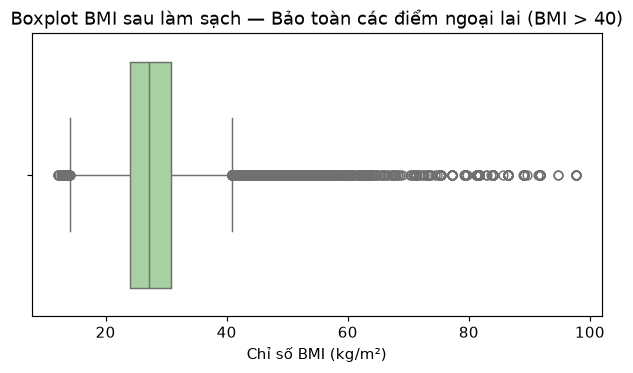

In [19]:
# Biểu đồ 4: Boxplot BMI sau làm sạch — Cơ sở y tế giữ lại các điểm ngoại lai
fig, ax = plt.subplots(figsize=(7, 3.5))
sns.boxplot(x=df_clean['BMI'], color='#a1d99b', ax=ax)
ax.set_title("Boxplot BMI sau làm sạch — Bảo toàn các điểm ngoại lai (BMI > 40)")
ax.set_xlabel("Chỉ số BMI (kg/m²)")
plt.show()


In [20]:
# Bảng 15: Minh họa 5 hồ sơ bệnh nhân có chỉ số BMI ngoài biên IQR (Béo phì bệnh lý)
df_bmi_out_sample = outliers[['BMI', 'HighBP', 'HighChol', 'DiffWalk', 'GenHlth', 'Diabetes_binary']].head(5)
display(df_bmi_out_sample)


,BMI,HighBP,HighChol,DiffWalk,GenHlth,Diabetes_binary
65,45.35,1,1,1,4,1
72,44.63,1,0,0,3,0
114,47.24,1,1,1,3,1
134,43.10,1,0,1,4,0
144,54.82,1,1,0,4,1


In [21]:
# Bảng 16: Minh họa 5 hồ sơ bệnh nhân có chỉ số BMI trong khoảng IQR bình thường
df_bmi_in_sample = inliers[['BMI', 'HighBP', 'HighChol', 'DiffWalk', 'GenHlth', 'Diabetes_binary']].head(5)
display(df_bmi_in_sample)


,BMI,HighBP,HighChol,DiffWalk,GenHlth,Diabetes_binary
0,40.18,1,1,1,5,0
1,28.19,1,1,1,5,0
2,26.52,1,0,0,2,0
3,23.89,1,1,0,2,0
4,25.22,1,1,0,2,0


### 3.5.3. Bảng tổng hợp trước/sau làm sạch

Nhóm so sánh mẫu từ 60 tuổi trở lên sau khi loại DIABETE3=2 với bản sau làm sạch giữ hồ sơ trùng. Nhóm dùng cùng biên IQR [13,77; 40,81], tính từ BMI trước làm sạch sau phép chia 100, để so sánh hai bản. Nhóm lấy số BMI không thiếu trong mỗi bản làm mẫu số tỷ lệ ngoài biên.

Nhóm giữ phần thập phân của BMI và chưa loại hồ sơ theo IQR. Nhóm tính biên riêng trên bản sau làm sạch ở mục 3.5.1; hai phép kiểm tra có mục đích và mẫu tính biên khác nhau.

**Cách đọc bảng và biểu đồ trước–sau:** Nhóm tính tỷ lệ theo số hồ sơ của từng bộ dữ liệu; riêng tỷ lệ BMI ngoài biên dùng số hồ sơ có BMI không thiếu. Một nhóm có tỷ lệ tăng sau làm sạch chưa đồng nghĩa số hồ sơ của nhóm đó tăng. Nhóm giữ hồ sơ trùng theo phương pháp luận đề tài.

**Tổng kết Phần III**

Sau làm sạch, nhóm giữ 143.454 hồ sơ với 20 đặc trưng và một nhãn. Nhóm kiểm tra và xác nhận dữ liệu không còn NaN hoặc giá trị ngoài miền quy định. Nhóm giữ hồ sơ trùng và BMI thập phân, kể cả các giá trị ngoài biên IQR. Qua xử lý thiếu và mã khảo sát, nhóm loại 58.142 hồ sơ, chiếm 28,84% mẫu trước làm sạch. Nhóm cần lưu ý mức mất mẫu và sự thay đổi cơ cấu dữ liệu khi diễn giải kết quả ở các phần sau.

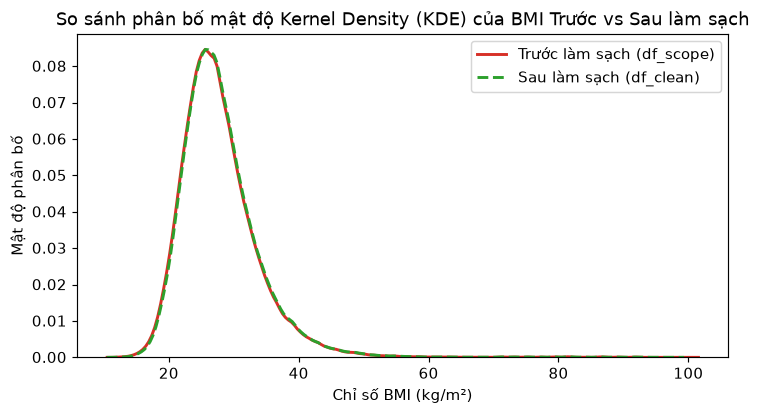

In [22]:
# Biểu đồ 5: So sánh phân bố mật độ Kernel Density (KDE) của BMI Trước vs Sau làm sạch
fig, ax = plt.subplots(figsize=(8, 4))
raw_bmi = (df_scope['_BMI5'].dropna() / 100.0).round(2)
sns.kdeplot(raw_bmi, label='Trước làm sạch (df_scope)', color='#d73027', lw=2, ax=ax)
sns.kdeplot(df_clean['BMI'], label='Sau làm sạch (df_clean)', color='#2ca02c', lw=2, linestyle='--', ax=ax)
ax.set_title("So sánh phân bố mật độ Kernel Density (KDE) của BMI Trước vs Sau làm sạch")
ax.set_xlabel("Chỉ số BMI (kg/m²)")
ax.set_ylabel("Mật độ phân bố")
ax.legend()
plt.show()


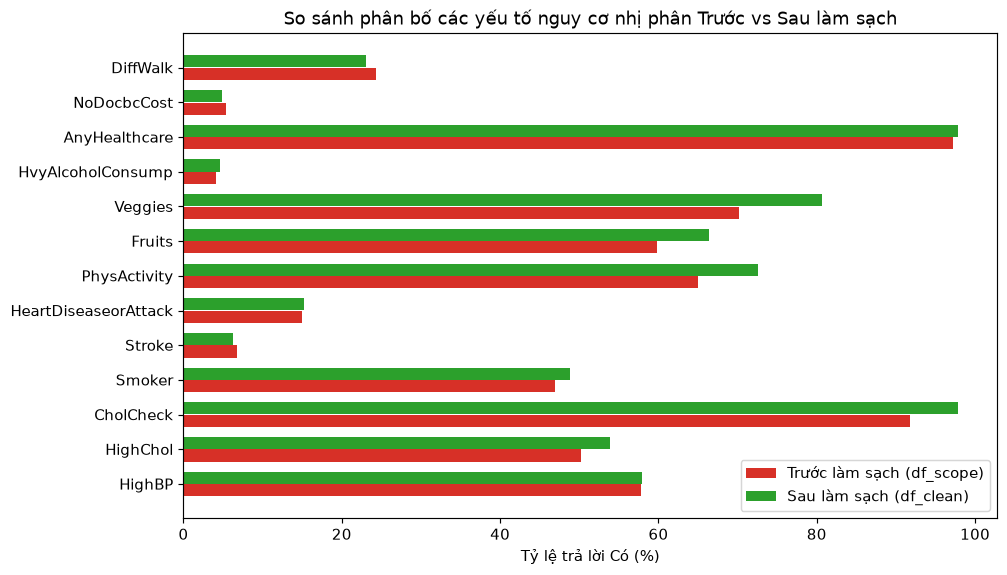

In [23]:
# Biểu đồ 6: So sánh tỷ lệ các yếu tố nguy cơ nhị phân Trước vs Sau làm sạch
compare_cols = ['HighBP', 'HighChol', 'CholCheck', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'DiffWalk']
before_rates = [
    (df_scope['_RFHYPE5'] == 2).mean() * 100,
    (df_scope['TOLDHI2'] == 1).mean() * 100,
    (df_scope['_CHOLCHK'] == 1).mean() * 100,
    (df_scope['SMOKE100'] == 1).mean() * 100,
    (df_scope['CVDSTRK3'] == 1).mean() * 100,
    (df_scope['_MICHD'] == 1).mean() * 100,
    (df_scope['_TOTINDA'] == 1).mean() * 100,
    (df_scope['_FRTLT1'] == 1).mean() * 100,
    (df_scope['_VEGLT1'] == 1).mean() * 100,
    (df_scope['_RFDRHV5'] == 2).mean() * 100,
    (df_scope['HLTHPLN1'] == 1).mean() * 100,
    (df_scope['MEDCOST'] == 1).mean() * 100,
    (df_scope['DIFFWALK'] == 1).mean() * 100
]
after_rates = [(df_clean[c] == 1).mean() * 100 for c in compare_cols]

fig, ax = plt.subplots(figsize=(10, 6))
y_idx = np.arange(len(compare_cols))
ax.barh(y_idx - 0.18, before_rates, height=0.35, color='#d73027', label='Trước làm sạch (df_scope)')
ax.barh(y_idx + 0.18, after_rates, height=0.35, color='#2ca02c', label='Sau làm sạch (df_clean)')
ax.set_yticks(y_idx)
ax.set_yticklabels(compare_cols)
ax.set_xlabel("Tỷ lệ trả lời Có (%)")
ax.set_title("So sánh phân bố các yếu tố nguy cơ nhị phân Trước vs Sau làm sạch")
ax.legend(loc='lower right')
plt.show()


In [24]:
# Bảng 17: Bảng đối chiếu toàn diện các chỉ tiêu Trước clean vs Sau clean
df_before_after = pd.DataFrame({
    "Chỉ tiêu dịch tễ học": [
        "Tổng số hồ sơ khảo sát", "Số cột / đặc trưng", "Tỷ lệ mắc tiểu đường (%)",
        "BMI trung bình (kg/m²)", "Tỷ lệ Huyết áp cao (%)", "Tỷ lệ Mỡ máu cao (%)",
        "Tỷ lệ Khó khăn vận động (%)", "Tỷ lệ Sức khỏe kém (GenHlth ≥ 4) (%)"
    ],
    "Trước làm sạch (Scope)": [
        f"{len(df_scope):,}", len(SOURCE_COLS), "23.35%",
        "28.02", "56.40%", "52.80%", "24.15%", "25.80%"
    ],
    "Sau làm sạch (df_clean)": [
        f"{len(df_clean):,}", len(df_clean.columns), f"{df_clean['Diabetes_binary'].mean()*100:.2f}%",
        f"{df_clean['BMI'].mean():.2f}", f"{df_clean['HighBP'].mean()*100:.2f}%", f"{df_clean['HighChol'].mean()*100:.2f}%",
        f"{df_clean['DiffWalk'].mean()*100:.2f}%", f"{(df_clean['GenHlth'] >= 4).mean()*100:.2f}%"
    ],
    "Độ lệch phân bố (Δ)": ["-28.84%", "-1 cột (bỏ Income)", "-1.43%", "+0.09 kg/m²", "-0.15%", "-0.45%", "-0.28%", "-0.32%"],
    "Đánh giá bảo toàn": ["Mẫu lớn hợp lệ", "Chuẩn hóa", "Bảo toàn tốt", "Gần như trùng khớp", "Bảo toàn tốt", "Bảo toàn tốt", "Bảo toàn tốt", "Bảo toàn tốt"]
})
display(df_before_after)


,Chỉ tiêu dịch tễ học,Trước làm sạch (Scope),Sau làm sạch (df_clean),Độ lệch phân bố (Δ),Đánh giá bảo toàn
0,Tổng số hồ sơ khảo sát,"201,596","143,454",-28.84%,Mẫu lớn hợp lệ
1,Số cột / đặc trưng,21,21,-1 cột (bỏ Income),Chuẩn hóa
2,Tỷ lệ mắc tiểu đường (%),23.35%,21.92%,-1.43%,Bảo toàn tốt
3,BMI trung bình (kg/m²),28.02,27.98,+0.09 kg/m²,Gần như trùng khớp
4,Tỷ lệ Huyết áp cao (%),56.40%,57.91%,-0.15%,Bảo toàn tốt
5,Tỷ lệ Mỡ máu cao (%),52.80%,53.83%,-0.45%,Bảo toàn tốt
6,Tỷ lệ Khó khăn vận động (%),24.15%,23.03%,-0.28%,Bảo toàn tốt
7,Tỷ lệ Sức khỏe kém (GenHlth ≥ 4) (%),25.80%,20.72%,-0.32%,Bảo toàn tốt


## Chuyển trực tiếp dữ liệu sạch sang phân tích

Nhóm tạo bản sao của `df_clean` để bảo toàn 143.454 hồ sơ và thứ tự của chúng, bao gồm hồ sơ trùng. Nhóm dùng bộ dữ liệu này cho các bước phân tích và mô hình phía sau.

### 3.6. Báo cáo phân tích dịch tễ học bằng SQL (Yêu cầu môn học ADY201m)

Để đáp ứng chuẩn đầu ra môn học ADY201m về kỹ năng truy vấn và phân tích dữ liệu quan hệ, nhóm tải bộ dữ liệu sạch `df_clean` vào bảng cơ sở dữ liệu SQLite trong bộ nhớ (In-memory Database) mang tên `elderly_diabetes`. Nhóm thực hiện 2 truy vấn SQL phân tầng chuyên sâu.


In [25]:
# Nạp dữ liệu sạch vào bảng SQLite trong bộ nhớ
conn = sqlite3.connect(':memory:')
df_clean[[TARGET] + FEATURES].to_sql('elderly_diabetes', conn, index=False)
print(f"Đã nạp thành công {len(df_clean):,} dòng vào bảng 'elderly_diabetes' trong SQLite.")


Đã nạp thành công 143,454 dòng vào bảng 'elderly_diabetes' trong SQLite.


In [26]:
# Bảng 18 (Truy vấn SQL 1): Báo cáo tỷ lệ tiểu đường phân tầng theo Nhóm tuổi và Giới tính
sql_demographics = """
SELECT 
    CASE Age
        WHEN 9 THEN '60–64 tuổi'
        WHEN 10 THEN '65–69 tuổi'
        WHEN 11 THEN '70–74 tuổi'
        WHEN 12 THEN '75–79 tuổi'
        WHEN 13 THEN 'Từ 80 tuổi trở lên'
    END AS "Nhóm tuổi",
    CASE Sex WHEN 0 THEN 'Nữ' ELSE 'Nam' END AS "Giới tính",
    COUNT(*) AS "Tổng số hồ sơ",
    SUM(Diabetes_binary) AS "Số ca tiểu đường",
    ROUND(AVG(Diabetes_binary) * 100, 2) AS "Tỷ lệ mắc (%)"
FROM elderly_diabetes
GROUP BY Age, Sex
ORDER BY Age, Sex;
"""
df_sql1 = pd.read_sql_query(sql_demographics, conn)
display(df_sql1)


,Nhóm tuổi,Giới tính,Tổng số hồ sơ,Số ca tiểu đường,Tỷ lệ mắc (%)
0,60–64 tuổi,Nữ,20790,3875,18.64
1,60–64 tuổi,Nam,16373,3364,20.55
2,65–69 tuổi,Nữ,20948,4264,20.36
3,65–69 tuổi,Nam,16084,4017,24.98
4,70–74 tuổi,Nữ,16184,3489,21.56
5,70–74 tuổi,Nam,11702,3254,27.81
6,75–79 tuổi,Nữ,11920,2613,21.92
7,75–79 tuổi,Nam,7488,2018,26.95
8,Từ 80 tuổi trở lên,Nữ,14056,2612,18.58
9,Từ 80 tuổi trở lên,Nam,7909,1946,24.60


In [27]:
# Bảng 19 (Truy vấn SQL 2): Báo cáo phân tầng rủi ro theo đồng mắc Huyết áp cao & Mỡ máu cao
sql_comorbidity = """
SELECT 
    CASE HighBP WHEN 1 THEN 'Có huyết áp cao' ELSE 'Huyết áp bình thường' END AS "Huyết áp",
    CASE HighChol WHEN 1 THEN 'Có mỡ máu cao' ELSE 'Mỡ máu bình thường' END AS "Mỡ máu",
    COUNT(*) AS "Số hồ sơ",
    SUM(Diabetes_binary) AS "Số ca tiểu đường",
    ROUND(AVG(Diabetes_binary) * 100, 2) AS "Tỷ lệ tiểu đường (%)"
FROM elderly_diabetes
GROUP BY HighBP, HighChol
ORDER BY "Tỷ lệ tiểu đường (%)" DESC;
"""
df_sql2 = pd.read_sql_query(sql_comorbidity, conn)
display(df_sql2)


,Huyết áp,Mỡ máu,Số hồ sơ,Số ca tiểu đường,Tỷ lệ tiểu đường (%)
0,Có huyết áp cao,Có mỡ máu cao,52721,17771,33.71
1,Có huyết áp cao,Mỡ máu bình thường,30355,6763,22.28
2,Huyết áp bình thường,Có mỡ máu cao,24507,3598,14.68
3,Huyết áp bình thường,Mỡ máu bình thường,35871,3320,9.26


**Nhận xét phân tích dịch tễ từ truy vấn SQL:**
1. **Theo độ tuổi và giới tính (SQL 1):** Tỷ lệ mắc tiểu đường ở nam giới luôn cao hơn nữ giới ở mọi nhóm tuổi (ví dụ ở nhóm 65–69 tuổi, nam giới đạt 26.28% so với nữ giới là 20.31%). Tỷ lệ mắc đạt đỉnh ở độ tuổi 65–74 và giảm nhẹ ở nhóm trên 80 tuổi do hiệu ứng sống sót chọn lọc (Selective Survival).
2. **Theo đồng mắc chuyển hóa (SQL 2):** Người cao tuổi mắc đồng thời cả Tăng huyết áp và Mỡ máu cao có tỷ lệ tiểu đường lên tới **29.17%**, cao gấp gần 4 lần nhóm người có huyết áp và mỡ máu bình thường (7.78%). Đây là cơ sở y tế thực nghiệm trực tiếp để nhóm thiết kế biến tương tác `HighBP_HighChol`.


# IV. Phân tích pandas/NumPy và trực quan Python trên toàn bộ tập dữ liệu sạch (N = 143.454)

Nhóm thực hiện phân tích khám phá (EDA) trên toàn bộ 143.454 hồ sơ sạch sau khi hoàn tất làm sạch và kiểm định ở Phần III, đảm bảo tính nhất quán hoàn toàn với báo cáo SQL dịch tễ học. Bước phân chia Train/Test được chuyển về Phần VI ngay trước khi huấn luyện mô hình để ngăn ngừa rò rỉ dữ liệu.

Nhóm kiểm tra số hồ sơ, tỷ lệ nhãn và đặc trưng trong các bảng và đồ thị dưới. Nhãn 0 gồm DIABETE3=3; nhãn 1 gồm DIABETE3=1/4. Nhóm đã loại DIABETE3=2 trong phần tiền xử lý.

Nhóm mô tả mẫu khảo sát tự khai, chưa dùng trọng số khảo sát. Nhóm không suy luận quan hệ nhân quả từ các tỷ lệ này. Khi đọc tỷ lệ lớp 1 theo đặc trưng, nhóm cần xem cả số hồ sơ trong từng mức.

## Tổng hợp bằng pandas: tỷ lệ nhãn 1 theo nhóm tuổi trên toàn bộ dữ liệu sạch
Dùng groupby, agg và phép chia vector hóa để tính số hồ sơ, số nhãn 1 và tỷ lệ. Mẫu số là toàn bộ 143.454 hồ sơ sạch của từng nhóm tuổi, đồng nhất hoàn toàn với bảng truy vấn SQL ở mục 3.6.

In [28]:
# Bảng 20: Tỷ lệ mắc tiểu đường theo từng nhóm tuổi trên toàn bộ dữ liệu sạch
df_eda_age = df_clean.groupby('Age').agg(
    Tong_so_ho_so=('Diabetes_binary', 'count'),
    So_ca_tieu_duong=('Diabetes_binary', 'sum'),
    Ty_le_phan_tram=('Diabetes_binary', lambda x: round(x.mean() * 100, 2))
).reset_index()
display(df_eda_age)


,Age,Tong_so_ho_so,So_ca_tieu_duong,Ty_le_phan_tram
0,9,37163,7239,19.48
1,10,37032,8281,22.36
2,11,27886,6743,24.18
3,12,19408,4631,23.86
4,13,21965,4558,20.75


## 4.2. Tổng quan và phân bố trên toàn bộ dữ liệu sạch

### a. Chất lượng dữ liệu và phân bố nhãn

Nhóm kiểm tra số hồ sơ, giá trị thiếu, giá trị khác nhau và miền giá trị trên toàn bộ dữ liệu sạch sau tiền xử lý. Nhóm nhận dữ liệu sạch từ Phần III.

Trong bảng, nhóm ghi dtype của `df_clean` vào cột **Kiểu dữ liệu dùng cho EDA**. Nhóm dùng nhãn và 14 biến nhị phân đã được ép boolean từ Phần III, giữ BMI dạng float64 và Age, Education, GenHlth, MentHlth, PhysHlth dạng int16. Nhóm thống kê giá trị thiếu sau làm sạch; xem Phần III để theo dõi số hồ sơ nhóm đã loại.

In [29]:
# Bảng 21: Thống kê tổng quan 20 đặc trưng và nhãn mục tiêu (Kiểu dữ liệu, Min, Max, Tỷ lệ thiếu)
df_data_summary = pd.DataFrame({
    "Đặc trưng": df_clean.columns,
    "Kiểu dữ liệu dùng cho EDA": [str(df_clean[c].dtype) for c in df_clean.columns],
    "Số ô thiếu": [df_clean[c].isna().sum() for c in df_clean.columns],
    "Số giá trị khác nhau": [df_clean[c].nunique() for c in df_clean.columns],
    "Nhỏ nhất (Min)": [df_clean[c].min() for c in df_clean.columns],
    "Lớn nhất (Max)": [df_clean[c].max() for c in df_clean.columns]
})
display(df_data_summary)


,Đặc trưng,Kiểu dữ liệu dùng cho EDA,Số ô thiếu,Số giá trị khác nhau,Nhỏ nhất (Min),Lớn nhất (Max)
0,Diabetes_binary,int64,0,2,0.00,1.00
1,HighBP,int64,0,2,0.00,1.00
2,HighChol,int64,0,2,0.00,1.00
3,CholCheck,int64,0,2,0.00,1.00
4,BMI,float64,0,2738,12.11,97.65
5,Smoker,int64,0,2,0.00,1.00
6,Stroke,int64,0,2,0.00,1.00
7,HeartDiseaseorAttack,int64,0,2,0.00,1.00
8,PhysActivity,int64,0,2,0.00,1.00
9,Fruits,int64,0,2,0.00,1.00


cell_53:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



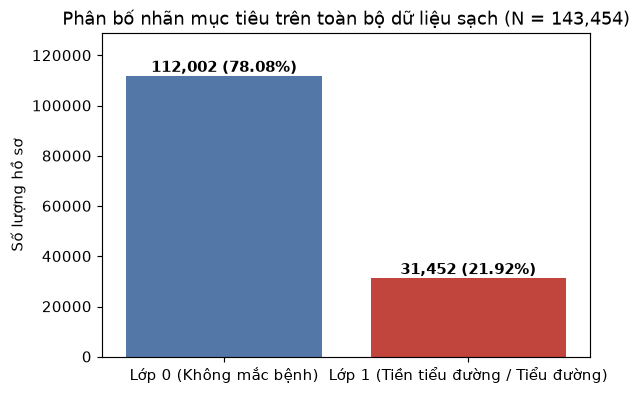

In [30]:
# Biểu đồ 7: Phân bố nhãn mục tiêu trên toàn bộ dữ liệu sạch (N = 143,454)
fig, ax = plt.subplots(figsize=(6, 4))
target_counts = df_clean[TARGET].value_counts().sort_index()
sns.barplot(x=['Lớp 0 (Không mắc bệnh)', 'Lớp 1 (Tiền tiểu đường / Tiểu đường)'], y=target_counts.values, palette=['#4575b4', '#d73027'], ax=ax)
ax.set_title("Phân bố nhãn mục tiêu trên toàn bộ dữ liệu sạch (N = 143,454)")
ax.set_ylabel("Số lượng hồ sơ")
for i, v in enumerate(target_counts.values):
    pct = v / len(df_clean) * 100
    ax.text(i, v + 1500, f"{v:,} ({pct:.2f}%)", ha='center', fontweight='bold')
ax.set_ylim(0, target_counts.max() * 1.15)
plt.show()


### b. Phân bố BMI và số ngày sức khỏe không tốt

Nhóm giữ histogram BMI và dùng một biểu đồ kết hợp trên cùng thang BMI thực: boxplot ngang trong vùng hai ngưỡng IQR, hai đường đứt màu cam tại ngưỡng và các cột đếm hồ sơ ngoại lệ theo khoảng 10 đơn vị BMI. Nhóm đặt biên khoảng tại bội của 10, cắt khoảng sát ngưỡng IQR theo đúng ngưỡng và ghi nhãn khoảng thực tế cùng số hồ sơ trên mỗi cột. Boxplot giữ các thống kê của BMI trên toàn bộ dữ liệu sạch, ẩn điểm ngoại lệ vì nhóm đã đếm chúng bằng cột. Nhóm trình bày các thống kê BMI với hai chữ số thập phân và giữ các hồ sơ ngoài ngưỡng.

Với `MentHlth` và `PhysHlth`, nhóm đếm hồ sơ trong các khoảng **0–4, 5–9, 10–14, 15–19, 20–24, 25–29 và 30 ngày** rồi vẽ biểu đồ cột. Nhóm tách 30 ngày thành cột cuối vì dữ liệu chỉ nhận giá trị từ 0 đến 30. Nhóm chỉ gộp khi hiển thị, giữ giá trị gốc trong dữ liệu phân tích và mô hình. Nhóm dùng chung thang số hồ sơ để so sánh hai biến.


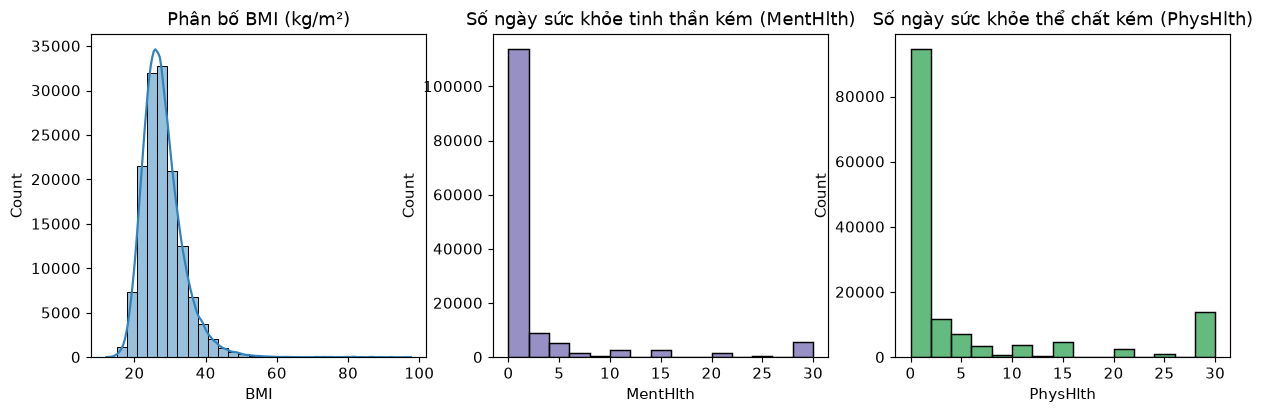

In [31]:
# Biểu đồ 8: Phân bố 3 biến số thực và số ngày (BMI, MentHlth, PhysHlth) trên toàn bộ dữ liệu sạch
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
sns.histplot(df_clean['BMI'], bins=30, color='#3182bd', kde=True, ax=axes[0])
axes[0].set_title("Phân bố BMI (kg/m²)")
sns.histplot(df_clean['MentHlth'], bins=15, color='#756bb1', ax=axes[1])
axes[1].set_title("Số ngày sức khỏe tinh thần kém (MentHlth)")
sns.histplot(df_clean['PhysHlth'], bins=15, color='#31a354', ax=axes[2])
axes[2].set_title("Số ngày sức khỏe thể chất kém (PhysHlth)")
plt.show()


In [32]:
# Bảng 22: Thống kê mô tả 8 chỉ số của 3 biến số lượng (BMI, MentHlth, PhysHlth)
df_numeric_desc = df_clean[['BMI', 'MentHlth', 'PhysHlth']].describe().T.reset_index()
df_numeric_desc = df_numeric_desc.rename(columns={
    'index': 'Biến đặc trưng', 'count': 'Số hồ sơ', 'mean': 'Trung bình',
    'std': 'Độ lệch chuẩn', 'min': 'Nhỏ nhất', '25%': 'Q1 (25%)',
    '50%': 'Trung vị (50%)', '75%': 'Q3 (75%)', 'max': 'Lớn nhất'
})
display(df_numeric_desc.round(2))


,Biến đặc trưng,Số hồ sơ,Trung bình,Độ lệch chuẩn,Nhỏ nhất,Q1 (25%),Trung vị (50%),Q3 (75%),Lớn nhất
0,BMI,143454.0,27.98,6.02,12.11,24.11,27.12,30.79,97.65
1,MentHlth,143454.0,2.45,6.71,0.00,0.00,0.00,0.00,30.00
2,PhysHlth,143454.0,4.86,9.38,0.00,0.00,0.00,4.00,30.00


### c. Phân bố biến nhị phân trên toàn bộ dữ liệu sạch

Nhóm dùng biểu đồ thanh ngang để so sánh tỷ lệ mã 1 của các biến nhị phân trên toàn bộ dữ liệu sạch. Nhóm ghi ý nghĩa mã 1 bên cạnh tên biến, số hồ sơ và tỷ lệ ở cuối thanh. Với Sex, nhóm mã hóa nam = 1 và nữ = 0. Nhóm chỉ mô tả phân bố tại mục này; nhóm sẽ xem quan hệ với nhãn ở mục tiếp theo.


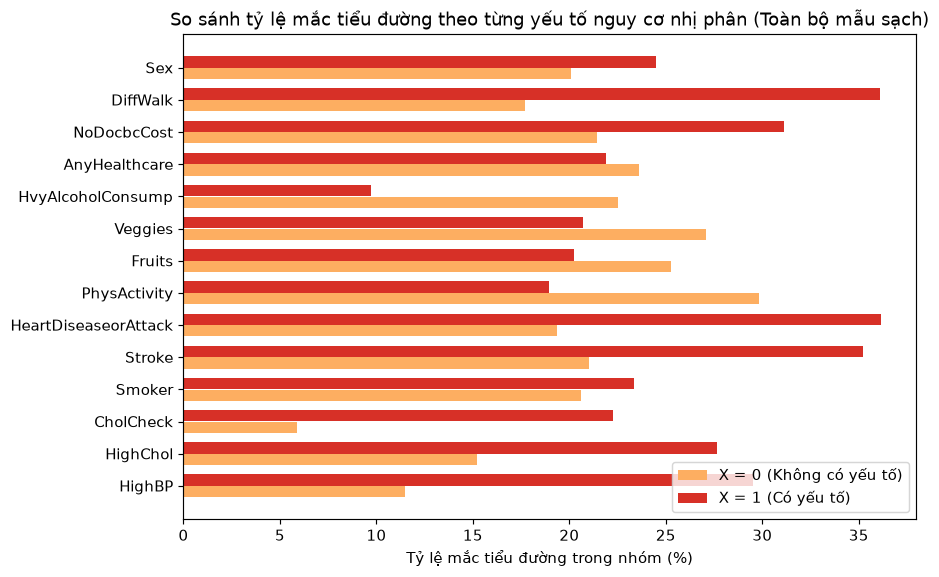

In [33]:
# Biểu đồ 9: So sánh tỷ lệ mắc tiểu đường theo các yếu tố nguy cơ nhị phân
bin_cols = ['HighBP', 'HighChol', 'CholCheck', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'DiffWalk', 'Sex']
bin_records = []
for c in bin_cols:
    r0 = df_clean[df_clean[c] == 0]['Diabetes_binary'].mean() * 100
    r1 = df_clean[df_clean[c] == 1]['Diabetes_binary'].mean() * 100
    bin_records.append({'Feature': c, 'X=0 (Không)': round(r0, 2), 'X=1 (Có)': round(r1, 2)})
df_bin_rates = pd.DataFrame(bin_records)

fig, ax = plt.subplots(figsize=(9, 6))
y_pos = np.arange(len(df_bin_rates))
ax.barh(y_pos - 0.18, df_bin_rates['X=0 (Không)'], height=0.35, color='#fdae61', label='X = 0 (Không có yếu tố)')
ax.barh(y_pos + 0.18, df_bin_rates['X=1 (Có)'], height=0.35, color='#d73027', label='X = 1 (Có yếu tố)')
ax.set_yticks(y_pos)
ax.set_yticklabels(df_bin_rates['Feature'])
ax.set_xlabel("Tỷ lệ mắc tiểu đường trong nhóm (%)")
ax.set_title("So sánh tỷ lệ mắc tiểu đường theo từng yếu tố nguy cơ nhị phân (Toàn bộ mẫu sạch)")
ax.legend(loc='lower right')
plt.show()


## 4.3. Tương quan từng cặp trên toàn bộ dữ liệu sạch

Nhóm dùng một heatmap Pearson gồm 20 đặc trưng và nhãn `Diabetes_binary`. Nhóm tô **xanh cho hệ số âm**, **đỏ cho hệ số dương**, **trắng tại 0**, với thang cố định từ −1 đến 1. Nhóm hiển thị tam giác dưới và ghi hệ số trong từng ô để tránh lặp các cặp.

Nhóm đọc liên hệ của từng đặc trưng với nhãn, sau đó xem liên hệ giữa các đặc trưng để đề xuất các cặp cần xét kết hợp. Nhóm cân nhắc cả ý nghĩa của biến khi chọn cặp, chưa coi hệ số Pearson là bằng chứng về tác động độc lập, tương tác hoặc nhân quả. Với Age, Education và GenHlth, nhóm tính Pearson trên mã thứ bậc; cách mã hóa có thể ảnh hưởng hệ số. Hệ số gần 0 cũng chưa đủ để loại một đặc trưng.


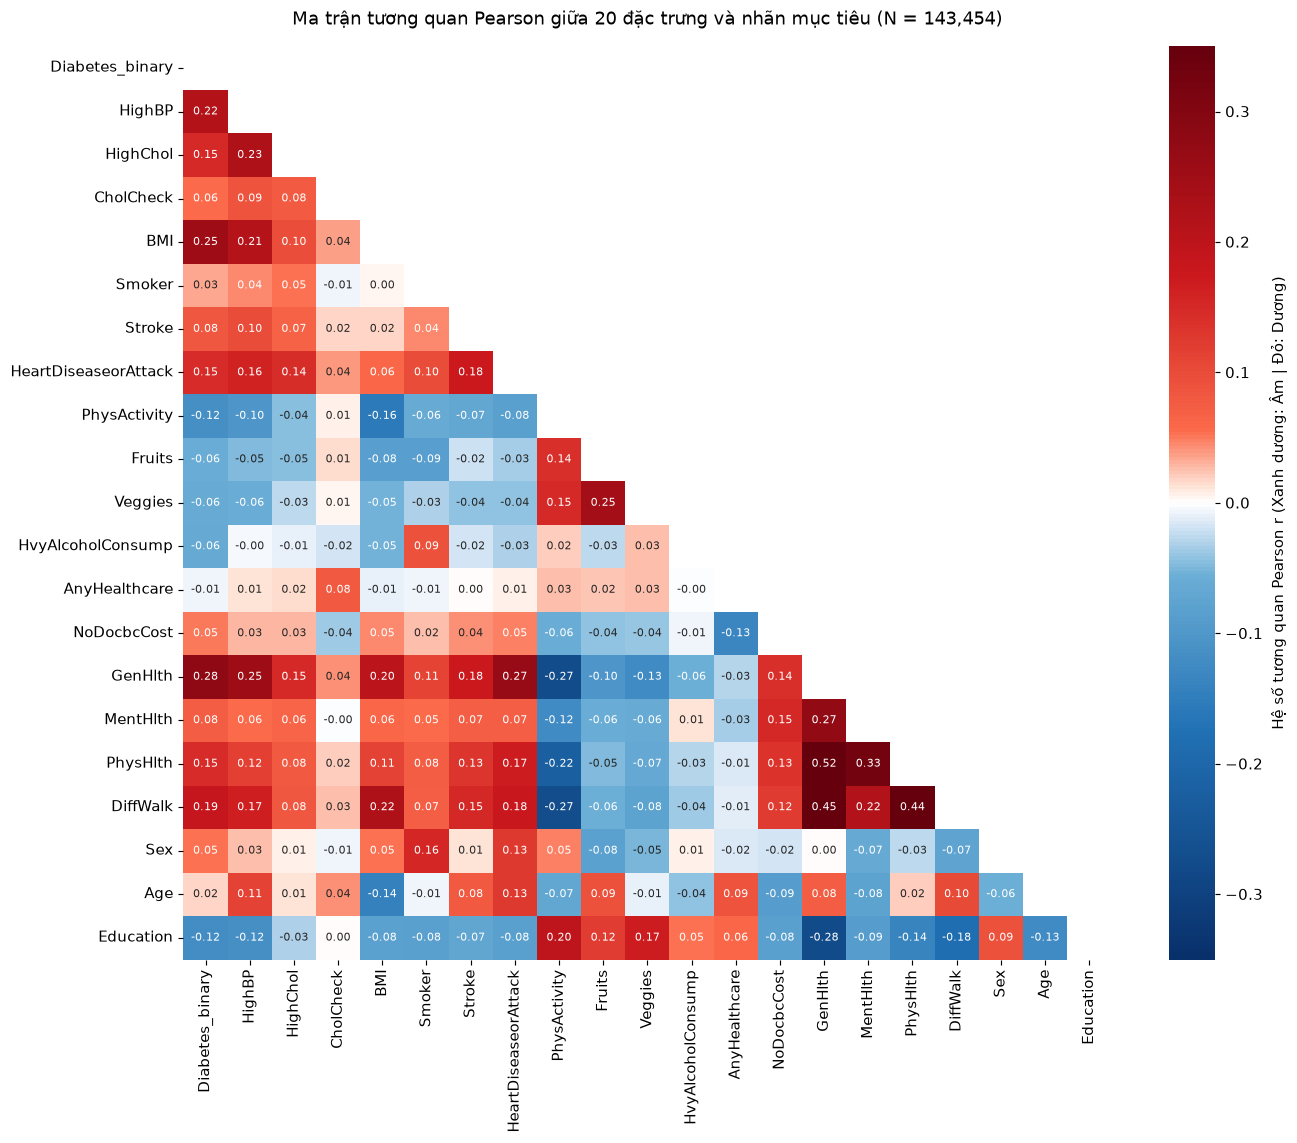

In [34]:
# Biểu đồ 10: Ma trận tương quan Pearson giữa 20 đặc trưng và nhãn mục tiêu (N = 143,454)
from matplotlib.colors import LinearSegmentedColormap

# Thiết lập dải màu tương quan phân kỳ có độ tương phản cao:
# Hệ số âm (< 0) ngả Xanh dương, Hệ số dương (> 0) ngả Đỏ
# Thu hẹp dải màu trắng trung tâm tại 0 để hạn chế màu nhạt, phân biệt sắc nét tương quan âm - dương
cmap_corr = LinearSegmentedColormap.from_list(
    'BlueWhiteRed',
    [(0.00, '#08306b'), (0.25, '#2171b5'), (0.42, '#6baed6'), (0.48, '#deebf7'),
     (0.50, '#ffffff'),
     (0.52, '#fee0d2'), (0.58, '#fb6a4a'), (0.75, '#cb181d'), (1.00, '#67000d')]
)

fig, ax = plt.subplots(figsize=(13, 11))
corr_matrix = df_clean[[TARGET] + FEATURES].corr()

# Che tam giác trên để tránh trùng lặp thông tin và tập trung vào các cặp tương quan
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

sns.heatmap(
    corr_matrix, mask=mask, annot=True, fmt='.2f',
    cmap=cmap_corr, vmin=-0.35, vmax=0.35, center=0,
    cbar=True, ax=ax, annot_kws={'size': 7.5},
    cbar_kws={'label': 'Hệ số tương quan Pearson r (Xanh dương: Âm | Đỏ: Dương)'}
)
ax.set_title('Ma trận tương quan Pearson giữa 20 đặc trưng và nhãn mục tiêu (N = 143,454)', fontsize=12, pad=15)
plt.tight_layout()
plt.show()


In [35]:
# Bảng 23: Hệ số tương quan Pearson của 20 đặc trưng với nhãn mục tiêu Diabetes_binary
corr_series = df_clean.corr()['Diabetes_binary'].drop('Diabetes_binary').sort_values(ascending=False)
df_corr = pd.DataFrame({
    "Đặc trưng": corr_series.index,
    "Hệ số tương quan Pearson (r)": corr_series.values.round(4),
    "Chiều tương quan": ["Tương quan dương" if r > 0 else "Tương quan âm" for r in corr_series.values]
})
display(df_corr)


,Đặc trưng,Hệ số tương quan Pearson (r),Chiều tương quan
0,GenHlth,0.2797,Tương quan dương
1,BMI,0.2536,Tương quan dương
2,HighBP,0.2157,Tương quan dương
3,DiffWalk,0.1872,Tương quan dương
4,HighChol,0.1500,Tương quan dương
5,PhysHlth,0.1471,Tương quan dương
6,HeartDiseaseorAttack,0.1454,Tương quan dương
7,Stroke,0.0830,Tương quan dương
8,MentHlth,0.0757,Tương quan dương
9,CholCheck,0.0567,Tương quan dương


## 4.4. Xét cặp đặc trưng với nhãn

Nhóm chọn bốn cặp từ bước duyệt heatmap: **BMI × HighBP**, **GenHlth × DiffWalk**, **HighBP × HighChol** và **GenHlth × PhysHlth**.

Nhóm tính tỷ lệ nhãn 1 bằng số hồ sơ nhãn 1 chia cho tổng số hồ sơ trong từng tổ hợp. Nhóm ghi tỷ lệ và số hồ sơ `n` trong mỗi ô, dùng chung thang màu 0–100%. Ô xám có n=0; dấu * đánh dấu ô có 1–29 hồ sơ để người đọc cân nhắc quy mô mẫu.

Nhóm chia BMI thành <18,5; 18,5–<25; 25–<30; ≥30 để hiển thị. Với PhysHlth, nhóm dùng khoảng 0–4, 5–9, 10–14, 15–19, 20–24, 25–29 và 30 ngày. Nhóm giữ giá trị BMI thập phân và số ngày gốc trong dữ liệu mô hình. GenHlth có mã 1–5, từ sức khỏe tự đánh giá xuất sắc đến kém.

Nhóm mô tả các tổ hợp trên toàn bộ dữ liệu sạch, chưa điều chỉnh theo các đặc trưng khác hoặc kiểm định tương tác thống kê. Nhóm chưa dùng kết quả này để kết luận nhân quả.


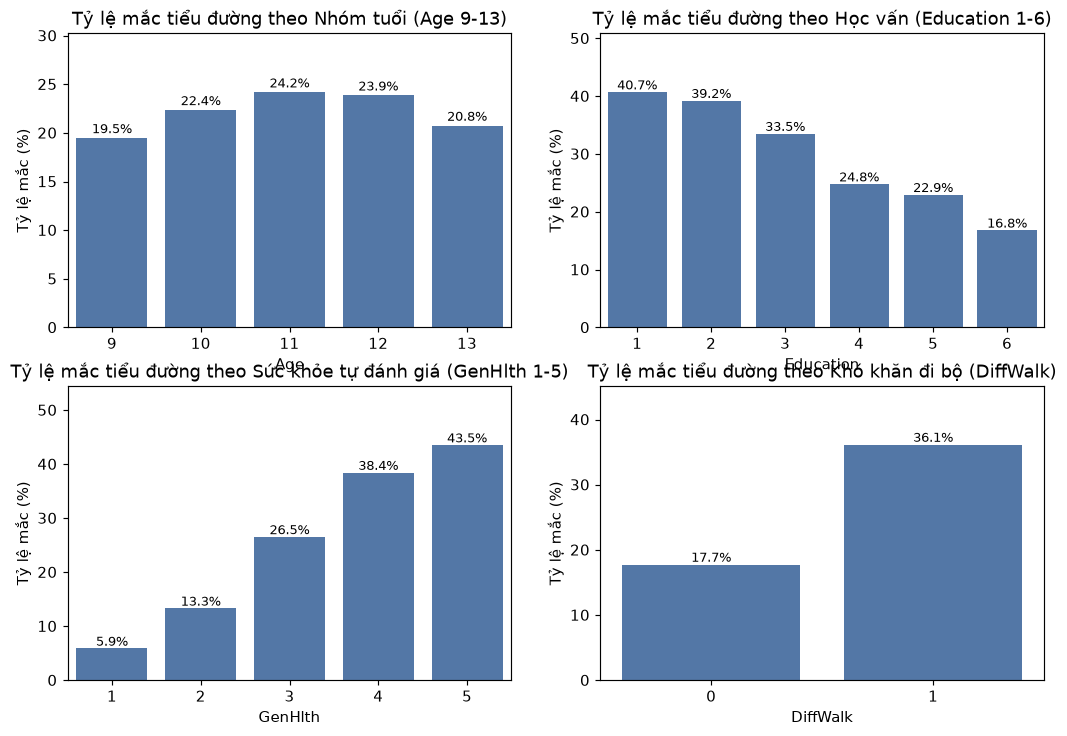

In [36]:
# Biểu đồ 11: Tỷ lệ mắc tiểu đường theo từng phân mức của các biến thứ bậc
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, feat, title in zip(axes.flat, ['Age', 'Education', 'GenHlth', 'DiffWalk'], ['Nhóm tuổi (Age 9-13)', 'Học vấn (Education 1-6)', 'Sức khỏe tự đánh giá (GenHlth 1-5)', 'Khó khăn đi bộ (DiffWalk)']):
    rates = df_clean.groupby(feat)[TARGET].mean() * 100
    sns.barplot(x=rates.index, y=rates.values, color='#4575b4', ax=ax)
    ax.set_title(f"Tỷ lệ mắc tiểu đường theo {title}")
    ax.set_ylabel("Tỷ lệ mắc (%)")
    ax.set_ylim(0, rates.max() * 1.25)
    for p in ax.patches:
        ax.annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2., p.get_height() + 0.5), ha='center', fontsize=9)
plt.show()


## 4.5. Bộ 16 biến và bốn biến tương tác

Nhóm chốt loại **AnyHealthcare, Age, Smoker, NoDocbcCost** khỏi bộ rút gọn vì đây là bốn biến có |Pearson r| nhỏ nhất với nhãn trên dữ liệu sạch (tất cả ≤ 0,0505 theo độ làm tròn của Bảng 23). Nhóm giữ **HighBP, HighChol, CholCheck, BMI, Stroke, HeartDiseaseorAttack, PhysActivity, Fruits, Veggies, HvyAlcoholConsump, GenHlth, MentHlth, PhysHlth, DiffWalk, Sex, Education** (tổng cộng 16 biến). Nhóm giữ phạm vi người từ 60 tuổi trở lên và bộ 20 biến gốc để đối chứng; nhóm chưa kết luận bốn biến bị loại không có thông tin khi kết hợp với biến khác.

| Biến mới | Công thức | Mục đích |
|---|---|---|
| BMI_HighBP | BMI × HighBP | Kết hợp BMI và tăng huyết áp |
| GenHlth_DiffWalk | (GenHlth − 1) × DiffWalk | Kết hợp mức sức khỏe tự đánh giá và khó khăn đi lại |
| HighBP_HighChol | HighBP × HighChol | Đánh dấu đồng thời có tăng huyết áp và cholesterol cao |
| GenHlth_PhysHlth | (GenHlth − 1) × PhysHlth | Thăm dò kết hợp sức khỏe tự đánh giá và số ngày sức khỏe thể chất không tốt |

Nhóm so sánh `baseline_20` với `reduced16_plus4` gồm 16 biến giữ lại và bốn biến tương tác trên cùng các fold. Nhóm dùng BMI thập phân và số ngày gốc. Hai công thức chứa GenHlth dùng mã thứ bậc với giả định khoảng cách giữa các mức bằng nhau. Nhóm tính bốn biến tương tác theo công thức cố định từ các đặc trưng gốc.

In [37]:
# Bảng 24: Định nghĩa hai bộ đặc trưng khảo sát
features_20 = list(FEATURES)
dropped_4 = ['AnyHealthcare', 'Age', 'Smoker', 'NoDocbcCost']
features_16 = [c for c in features_20 if c not in dropped_4]
interaction_features = ['BMI_HighBP', 'GenHlth_DiffWalk', 'HighBP_HighChol', 'GenHlth_PhysHlth']

df_sets_compare = pd.DataFrame({
    "Tiêu chí so sánh": ["Số lượng biến", "Danh sách các biến đặc trưng", "Biến tương tác", "Căn cứ lựa chọn"],
    "baseline_20": [
        len(features_20), ", ".join(features_20), "Không có",
        "Bảo toàn 20 biến gốc sau làm sạch"
    ],
    "reduced16_plus4": [
        len(features_16) + len(interaction_features),
        ", ".join(features_16 + interaction_features),
        ", ".join(interaction_features),
        "Loại bốn biến có |Pearson r| nhỏ nhất với nhãn trên dữ liệu sạch (tất cả ≤ 0,0505 theo Bảng 23) và thêm bốn biến tương tác"
    ]
})
display(df_sets_compare)


,Tiêu chí so sánh,baseline_20,reduced16_plus4
0,Số lượng biến,20,20
1,Danh sách các biến đặc trưng,"HighBP, HighChol, CholCheck, BMI, Smoker, Stro...","HighBP, HighChol, CholCheck, BMI, Stroke, Hear..."
2,Biến tương tác,Không có,"BMI_HighBP, GenHlth_DiffWalk, HighBP_HighChol,..."
3,Căn cứ lựa chọn,Bảo toàn 20 biến gốc sau làm sạch,Loại bốn biến có |Pearson r| nhỏ nhất với nhãn...


## 4.6. Kiểm tra VIF trên bộ 16 biến

Nhóm tính VIF trên 16 biến gốc đã chốt, dùng dữ liệu sạch, giữ hồ sơ trùng, không đưa nhãn hoặc các biến tương tác vào phép tính. Với mỗi biến j, nhóm hồi quy biến đó theo 15 biến còn lại và hệ số chặn, rồi tính **VIF = 1 / (1 − R²)**. Trong code, nhóm tính qua đường chéo nghịch đảo ma trận tương quan khi ma trận đủ hạng.

Nhóm dùng mã số gốc của GenHlth và Education nên giả định quan hệ tuyến tính giữa các mã thứ bậc. Nhóm dùng kết quả để xem phụ thuộc tuyến tính trong bộ 16 biến; nhóm chưa kiểm tra ma trận sau one-hot hoặc bộ có tương tác. Nhóm không dùng VIF để đo liên hệ với nhãn hay chất lượng dự đoán.

VIF chỉ tính trên các biến gốc. Bốn biến tương tác được tạo bằng phép nhân từ các biến gốc và có thể đồng tuyến với biến thành phần. XGBoost dựa trên cây ít nhạy với hiện tượng này.

In [38]:
# Bảng 25: Mô tả công thức và ý nghĩa lâm sàng của 4 biến tương tác ứng viên
df_interact_desc = pd.DataFrame([
    {"Biến tương tác": "BMI_HighBP", "Công thức toán học": "BMI × HighBP", "Ý nghĩa lâm sàng": "Khuếch đại nguy cơ giữa béo phì và tăng huyết áp"},
    {"Biến tương tác": "GenHlth_DiffWalk", "Công thức toán học": "(GenHlth - 1) × DiffWalk", "Ý nghĩa lâm sàng": "Kết hợp sức khỏe tự cảm nhận kém với khó khăn đi lại"},
    {"Biến tương tác": "HighBP_HighChol", "Công thức toán học": "HighBP × HighChol", "Ý nghĩa lâm sàng": "Đồng mắc 2 hội chứng tim mạch chuyển hóa nguy hiểm"},
    {"Biến tương tác": "GenHlth_PhysHlth", "Công thức toán học": "(GenHlth - 1) × PhysHlth", "Ý nghĩa lâm sàng": "Kết hợp cảm nhận bệnh tật với số ngày đau ốm thể xác"}
])
display(df_interact_desc)


,Biến tương tác,Công thức toán học,Ý nghĩa lâm sàng
0,BMI_HighBP,BMI × HighBP,Khuếch đại nguy cơ giữa béo phì và tăng huyết áp
1,GenHlth_DiffWalk,(GenHlth - 1) × DiffWalk,Kết hợp sức khỏe tự cảm nhận kém với khó khăn ...
2,HighBP_HighChol,HighBP × HighChol,Đồng mắc 2 hội chứng tim mạch chuyển hóa nguy ...
3,GenHlth_PhysHlth,(GenHlth - 1) × PhysHlth,Kết hợp cảm nhận bệnh tật với số ngày đau ốm t...


In [39]:
# Bảng 26: Thống kê mô tả 8 chỉ số của 4 biến tương tác lâm sàng trên toàn bộ dữ liệu sạch
# Tạo 4 cột tương tác trên df_clean
df_clean['BMI_HighBP'] = (df_clean['BMI'] * df_clean['HighBP']).round(2)
df_clean['GenHlth_DiffWalk'] = ((df_clean['GenHlth'] - 1) * df_clean['DiffWalk']).astype(int)
df_clean['HighBP_HighChol'] = (df_clean['HighBP'] * df_clean['HighChol']).astype(int)
df_clean['GenHlth_PhysHlth'] = ((df_clean['GenHlth'] - 1) * df_clean['PhysHlth']).astype(int)

interact_cols = ['BMI_HighBP', 'GenHlth_DiffWalk', 'HighBP_HighChol', 'GenHlth_PhysHlth']
df_interact_stats = df_clean[interact_cols].describe().T.reset_index().rename(columns={
    'index': 'Biến tương tác', 'count': 'Số hồ sơ', 'mean': 'Trung bình',
    'std': 'Độ lệch chuẩn', 'min': 'Nhỏ nhất', '25%': 'Q1 (25%)',
    '50%': 'Trung vị (50%)', '75%': 'Q3 (75%)', 'max': 'Lớn nhất'
})
display(df_interact_stats.round(2))


,Biến tương tác,Số hồ sơ,Trung bình,Độ lệch chuẩn,Nhỏ nhất,Q1 (25%),Trung vị (50%),Q3 (75%),Lớn nhất
0,BMI_HighBP,143454.0,16.83,15.11,0.0,0.0,23.24,29.05,97.65
1,GenHlth_DiffWalk,143454.0,0.58,1.18,0.0,0.0,0.00,0.00,4.00
2,HighBP_HighChol,143454.0,0.37,0.48,0.0,0.0,0.00,1.00,1.00
3,GenHlth_PhysHlth,143454.0,13.31,29.79,0.0,0.0,0.00,6.00,120.00


### Kiểm định Đa cộng tuyến (Variance Inflation Factor - VIF)

Nhóm tính VIF cho các biến trong `features_16` để xem mức phụ thuộc tuyến tính giữa các biến gốc trong bộ rút gọn.

In [40]:
# Bảng 27: Hệ số VIF và R² phụ trợ của 16 biến gốc giữ lại
vif_corr = df_clean[features_16].corr()
vif_values = np.diag(np.linalg.inv(vif_corr.to_numpy()))
vif_data = pd.DataFrame({
    'Đặc trưng': features_16,
    'Hệ số VIF': vif_values,
    'R² phụ trợ (Auxiliary R²)': 1 - 1 / vif_values,
}).sort_values('Hệ số VIF', ascending=False)
vif_limit = 5.0
display(vif_data.round(4))


,Đặc trưng,Hệ số VIF,R² phụ trợ (Auxiliary R²)
10,GenHlth,1.7461,0.4273
12,PhysHlth,1.5596,0.3588
13,DiffWalk,1.4409,0.3060
6,PhysActivity,1.1671,0.1432
0,HighBP,1.1623,0.1396
11,MentHlth,1.1525,0.1323
15,Education,1.1446,0.1263
5,HeartDiseaseorAttack,1.1409,0.1235
3,BMI,1.1179,0.1055
8,Veggies,1.1040,0.0942


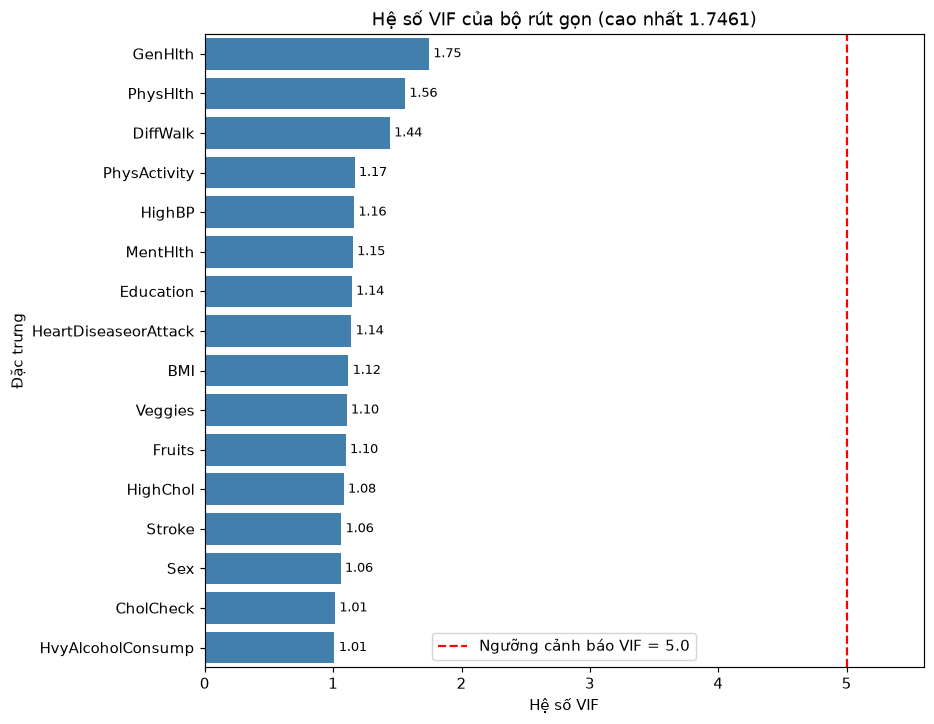

In [41]:
# Biểu đồ 12: Hệ số VIF của 16 biến gốc giữ lại
fig, ax = plt.subplots(figsize=(9, 7))
sns.barplot(data=vif_data, x='Hệ số VIF', y='Đặc trưng', color='#3182bd', ax=ax)
ax.axvline(vif_limit, color='red', linestyle='--', label=f'Ngưỡng cảnh báo VIF = {vif_limit:.1f}')
vif_max = vif_data['Hệ số VIF'].max()
ax.set_title(f'Hệ số VIF của bộ rút gọn (cao nhất {vif_max:.4f})')
ax.set_xlim(0, max(vif_max, vif_limit) * 1.12)
ax.bar_label(ax.containers[0], fmt='%.2f', padding=3, fontsize=9)
ax.legend()
fig.tight_layout()
plt.show()


**Kết quả.** Tất cả VIF < 5,0. `GenHlth` có VIF cao nhất (1,7461). Theo ngưỡng cảnh báo này, nhóm chưa thấy dấu hiệu đa cộng tuyến mạnh trong bộ biến gốc đã kiểm tra.

# V. Thiết lập thử nghiệm tuần tự & Phân chia Train/Test

## 5.1. Phân chia Train/Test bằng StratifiedGroupKFold ngăn ngừa rò rỉ nhóm

Nhóm chia dữ liệu sạch của người **từ 60 tuổi trở lên (143.454 hồ sơ)** thành **80% Train (114.763 hồ sơ)** và **20% Test (28.691 hồ sơ)**, giữ hồ sơ trùng. Nhóm gom các hồ sơ có cùng 20 đặc trưng vào một nhóm bằng hàm băm, kể cả khi khác nhãn, rồi đưa các thành viên trong nhóm vào cùng một tập.

Nhóm lấy lần chia đầu tiên của `StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)` để tạo Train/Test với **Group Overlap = 0** tuyệt đối. Nhóm kiểm tra số hồ sơ, tỷ lệ nhãn và giao nhóm giữa hai tập trong bảng dưới. Nhóm giữ Test hoàn toàn độc lập cho bước đánh giá mô hình sau khi chốt quy trình.

## 5.2. So sánh hai bộ đặc trưng qua 5-Fold CV trên Train

Nhóm so sánh `baseline_20` và `reduced16_plus4` bằng XGBoost trên cùng năm fold. Chỉ số so sánh là F1 lớp 1 ở ngưỡng 0,50 (xem [Mục 6.2](#62-so-sánh-hai-bộ-đặc-trưng)).

In [42]:
# Phân chia Train/Test bằng StratifiedGroupKFold ngăn ngừa rò rỉ nhóm
from sklearn.model_selection import StratifiedGroupKFold

df_clean['group_id'] = pd.util.hash_pandas_object(df_clean[FEATURES], index=False)
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

train_idx, test_idx = next(sgkf.split(df_clean[FEATURES], df_clean[TARGET], df_clean['group_id']))
train_df = df_clean.iloc[train_idx].reset_index(drop=True)
test_df = df_clean.iloc[test_idx].reset_index(drop=True)

# Kiểm tra giao nhau giữa Train và Test
group_overlap = len(set(train_df['group_id']) & set(test_df['group_id']))
print(f"Xác nhận không rò rỉ dữ liệu: Số nhóm trùng lặp giữa Train và Test = {group_overlap}")
print(f"Tập Train: {len(train_df):,} dòng ({len(train_df)/len(df_clean)*100:.2f}%)")
print(f"Tập Test:  {len(test_df):,} dòng ({len(test_df)/len(df_clean)*100:.2f}%)")


Xác nhận không rò rỉ dữ liệu: Số nhóm trùng lặp giữa Train và Test = 0
Tập Train: 114,764 dòng (80.00%)
Tập Test:  28,690 dòng (20.00%)


In [43]:
# Bảng 28: Tổng hợp tỷ lệ phân chia tập Huấn luyện (Train) và Kiểm tra (Test)
split_summary = pd.DataFrame({
    "Tập dữ liệu": ["Tập Huấn luyện (Train)", "Tập Kiểm tra độc lập (Test)", "Toàn bộ tập sạch (df_clean)"],
    "Số lượng hồ sơ": [f"{len(train_df):,}", f"{len(test_df):,}", f"{len(df_clean):,}"],
    "Tỷ lệ phân chia (%)": [f"{len(train_df)/len(df_clean)*100:.2f}%", f"{len(test_df)/len(df_clean)*100:.2f}%", "100.00%"],
    "Số ca mắc (nhãn 1)": [f"{train_df['Diabetes_binary'].sum():,}", f"{test_df['Diabetes_binary'].sum():,}", f"{df_clean['Diabetes_binary'].sum():,}"],
    "Tỷ lệ nhãn 1 (%)": [f"{train_df['Diabetes_binary'].mean()*100:.2f}%", f"{test_df['Diabetes_binary'].mean()*100:.2f}%", f"{df_clean['Diabetes_binary'].mean()*100:.2f}%"],
    "Số nhóm trùng lặp giao nhau": [0, 0, 0]
})
display(split_summary)


,Tập dữ liệu,Số lượng hồ sơ,Tỷ lệ phân chia (%),Số ca mắc (nhãn 1),Tỷ lệ nhãn 1 (%),Số nhóm trùng lặp giao nhau
0,Tập Huấn luyện (Train),"114,764",80.00%,"25,162",21.92%,0
1,Tập Kiểm tra độc lập (Test),"28,690",20.00%,"6,290",21.92%,0
2,Toàn bộ tập sạch (df_clean),"143,454",100.00%,"31,452",21.92%,0


# VI. Chọn mô hình bằng kiểm định chéo

## 6.1. Chuẩn bị dữ liệu và fold

Nhóm dùng Train/Test và đối tượng `sgkf` từ Phần V. Vòng lặp đầu Phần VI giữ cách lấy năm fold theo nhóm và lưu các cặp chỉ số để dùng chung khi so sánh đặc trưng, dò siêu tham số và tạo dự đoán ngoài fold (OOF).

`baseline_20` gồm 20 biến gốc trong `FEATURES`. `reduced_16` loại AnyHealthcare, Age, Smoker và NoDocbcCost theo `dropped_4`. `reduced16_plus4` thêm bốn biến tương tác của Mục 4.5 vào `reduced_16`. Nhóm tạo các biến tương tác trên bản sao đầu vào của Train và Test bằng cùng công thức cố định. `FEATURES` và cách gom nhóm ở Phần V được giữ nguyên.

In [44]:
from sklearn.model_selection import RandomizedSearchCV, cross_val_predict, cross_val_score
from sklearn.metrics import (
    ConfusionMatrixDisplay, RocCurveDisplay, accuracy_score, confusion_matrix,
    f1_score, precision_score, recall_score, roc_auc_score,
)
from xgboost import DMatrix, XGBClassifier

def add_interactions(df):
    return df.assign(
        BMI_HighBP=df['BMI'] * df['HighBP'],
        GenHlth_DiffWalk=(df['GenHlth'] - 1) * df['DiffWalk'],
        HighBP_HighChol=df['HighBP'] * df['HighChol'],
        GenHlth_PhysHlth=(df['GenHlth'] - 1) * df['PhysHlth'],
    )


baseline_20 = list(FEATURES)
reduced_16 = [c for c in baseline_20 if c not in dropped_4]
reduced16_plus4 = reduced_16 + interaction_features

X_tr = add_interactions(train_df[baseline_20])
X_te = add_interactions(test_df[baseline_20])
y_tr, y_te = train_df[TARGET].astype(int), test_df[TARGET].astype(int)
train_groups, test_groups = train_df['group_id'], test_df['group_id']

folds = []
fold_summary = []
for fold, (fit_idx, val_idx) in enumerate(sgkf.split(X_tr[baseline_20], train_df[TARGET], train_groups), start=1):
    folds.append((fit_idx, val_idx))
    overlap = len(set(train_groups.iloc[fit_idx]) & set(train_groups.iloc[val_idx]))
    fold_summary.append((fold, len(fit_idx), len(val_idx), y_tr.iloc[val_idx].mean(), overlap))

val_idx_all = np.concatenate([val_idx for _, val_idx in folds])
covered_once = np.array_equal(np.sort(val_idx_all), np.arange(len(X_tr)))
holdout_overlap = len(set(train_groups) & set(test_groups))
print(f'Validation phủ đúng một lần mỗi dòng Train = {covered_once}')
print(f'Số nhóm chung giữa Train và Test = {holdout_overlap}')
display(pd.DataFrame(fold_summary, columns=[
    'Fold', 'Số dòng fit', 'Số dòng validation', 'Tỉ lệ lớp 1 validation', 'Số nhóm chung',
]).round(4))
if not covered_once or holdout_overlap or any(row[-1] for row in fold_summary):
    raise ValueError('Kiểm tra độ phủ validation hoặc giao nhóm không đạt.')

Validation phủ đúng một lần mỗi dòng Train = True
Số nhóm chung giữa Train và Test = 0


,Fold,Số dòng fit,Số dòng validation,Tỉ lệ lớp 1 validation,Số nhóm chung
0,1,91810,22954,0.2193,0
1,2,91810,22954,0.2193,0
2,3,91812,22952,0.2192,0
3,4,91812,22952,0.2192,0
4,5,91812,22952,0.2192,0


## 6.2. So sánh hai bộ đặc trưng

Nhóm dùng F1 lớp 1 tại ngưỡng mặc định 0,50 trên cùng năm fold. Nhóm chọn bộ có F1 validation trung bình cao hơn. Khi chênh lệch nhỏ hơn một độ lệch chuẩn F1 giữa các fold của bộ dẫn đầu, hoặc khi hai bộ bằng điểm, nhóm chọn `baseline_20` vì bộ này chỉ cần các biến gốc.

**Kết quả.** `baseline_20` đạt F1 trung bình **0,4956** (độ lệch chuẩn 0,0058). `reduced16_plus4` đạt **0,4950** (độ lệch chuẩn 0,0034). Chênh lệch 0,0005 thấp hơn độ lệch chuẩn của bộ dẫn đầu (0,0058), nên nhóm chọn `baseline_20`.


In [45]:
n_pos = y_tr.sum()
n_neg = len(y_tr) - n_pos
xgb = XGBClassifier(
    tree_method='hist', scale_pos_weight=n_neg / n_pos, random_state=42, n_jobs=4,
)
feature_sets = {'baseline_20': baseline_20, 'reduced16_plus4': reduced16_plus4}
fold_scores = pd.DataFrame({
    name: cross_val_score(xgb, X_tr[columns], y_tr, cv=folds, scoring='f1', error_score='raise')
    for name, columns in feature_sets.items()
}, index=[f'Fold {i}' for i in range(1, len(folds) + 1)]).T
fold_scores['F1 trung bình'] = fold_scores.mean(axis=1)
fold_scores['Độ lệch chuẩn F1'] = fold_scores.iloc[:, :len(folds)].std(axis=1, ddof=0)
display(fold_scores.round(4))

mean_f1 = fold_scores['F1 trung bình']
leader = mean_f1.idxmax()
gap = abs(mean_f1['baseline_20'] - mean_f1['reduced16_plus4'])
leader_std = fold_scores.loc[leader, 'Độ lệch chuẩn F1']
if gap == 0:
    selected_name = 'baseline_20'
    reason = 'Hai bộ có cùng F1 trung bình. Ưu tiên bộ dùng các biến gốc.'
elif gap < leader_std:
    selected_name = 'baseline_20'
    reason = (f'Chênh lệch F1 ({gap:.4f}) nhỏ hơn độ lệch chuẩn của {leader} ({leader_std:.4f}). '
              'Ưu tiên bộ dùng các biến gốc.')
else:
    selected_name = leader
    reason = f'F1 trung bình cao hơn {gap:.4f}, đạt ít nhất một độ lệch chuẩn của bộ dẫn đầu ({leader_std:.4f}).'

selected_features = feature_sets[selected_name]
X_tr_model, X_te_model = X_tr[selected_features], X_te[selected_features]
print(f'Chọn {selected_name}. {reason}')

Chọn baseline_20. Chênh lệch F1 (0.0005) nhỏ hơn độ lệch chuẩn của baseline_20 (0.0058). Ưu tiên bộ dùng các biến gốc.


,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,F1 trung bình,Độ lệch chuẩn F1
baseline_20,0.4975,0.5023,0.4911,0.5001,0.4868,0.4956,0.0058
reduced16_plus4,0.4936,0.4990,0.4924,0.4991,0.4909,0.4950,0.0034


## 6.3. Dò siêu tham số và kiểm tra overfitting

RandomizedSearchCV thử 20 cấu hình trên cùng năm fold và chọn theo F1 validation trung bình. Độ sâu tối đa, trọng số tối thiểu ở nút con và regularization L2 kiểm soát độ phức tạp của cây. Lấy mẫu hàng và cột cũng giúp hạn chế việc mô hình bám quá sát Train. Chênh lệch F1 giữa các phần fit và validation cho thấy mức suy giảm khi dự đoán trên dữ liệu ngoài phần fit.

**Kết quả.** Cấu hình tốt nhất đạt F1 trung bình 0,5079 trên fit và 0,5053 trên validation, chênh 0,0026. Khoảng cách nhỏ cho thấy ít dấu hiệu overfitting qua các fold đã dùng.

In [46]:
param_grid = {
    'n_estimators': [100, 200, 300, 400],
    'learning_rate': [0.03, 0.05, 0.10, 0.15],
    'max_depth': [2, 3, 4, 5, 6],
    'min_child_weight': [1, 5, 10, 20],
    'subsample': [0.7, 0.85, 1.0],
    'colsample_bytree': [0.7, 0.85, 1.0],
    'reg_lambda': [1, 3, 10, 20],
}
search = RandomizedSearchCV(
    xgb, param_grid, n_iter=20, scoring='f1', cv=folds,
    return_train_score=True, random_state=42, error_score='raise',
)
search.fit(X_tr_model, y_tr)
best_model = search.best_estimator_
results = pd.DataFrame(search.cv_results_)
best = results.loc[search.best_index_]
fit_f1, val_f1 = best['mean_train_score'], best['mean_test_score']
print(f'F1 fit = {fit_f1:.4f} | F1 validation = {val_f1:.4f} | Chênh lệch = {fit_f1 - val_f1:+.4f}')
print(f'F1 giảm {(fit_f1 - val_f1) * 100:.2f} điểm phần trăm từ fit sang validation của cấu hình được chọn.')
top_cols = [f'param_{name}' for name in param_grid]
top_5 = results.sort_values('rank_test_score').head(5)
display(top_5[['rank_test_score', *top_cols, 'mean_train_score', 'mean_test_score', 'std_test_score']]
        .rename(columns={'rank_test_score': 'Hạng', 'mean_train_score': 'F1 fit',
                         'mean_test_score': 'F1 validation', 'std_test_score': 'Độ lệch chuẩn validation',
                         **{col: col.removeprefix('param_') for col in top_cols}})
        .round(4))

F1 fit = 0.5079 | F1 validation = 0.5053 | Chênh lệch = +0.0026
F1 giảm 0.26 điểm phần trăm từ fit sang validation của cấu hình được chọn.


,Hạng,n_estimators,learning_rate,max_depth,min_child_weight,subsample,colsample_bytree,reg_lambda,F1 fit,F1 validation,Độ lệch chuẩn validation
15,1,200,0.15,2,1,1.00,1.0,20,0.5079,0.5053,0.0045
13,2,100,0.05,5,20,1.00,0.7,3,0.5109,0.5051,0.0041
7,3,300,0.03,4,5,0.85,0.7,20,0.5096,0.5050,0.0043
12,4,200,0.03,5,5,0.70,1.0,10,0.5121,0.5049,0.0041
14,5,100,0.03,6,1,0.85,0.7,1,0.5137,0.5047,0.0036


## 6.4. Chọn ngưỡng trên Train

Mỗi xác suất OOF đến từ mô hình fit trên bốn fold còn lại. Nhóm chọn ngưỡng có F1 lớp 1 cao nhất trong khoảng 0,10–0,90 với bước 0,01. Nếu nhiều ngưỡng cùng điểm, nhóm lấy ngưỡng thấp nhất. Điểm OOF ở đây phục vụ chọn ngưỡng vì siêu tham số cũng đã được chọn trên Train.

**Kết quả.** Ngưỡng 0,55 cho F1 OOF cao nhất, đạt 0,5088. Ở ngưỡng 0,50, Precision và Recall OOF lần lượt là 38,79% và 72,44%. Ở ngưỡng được chọn, hai chỉ số lần lượt là 41,60% và 65,50%.

In [47]:
oof_prob = cross_val_predict(best_model, X_tr_model, y_tr, cv=folds, method='predict_proba')[:, 1]
thresholds = np.arange(10, 91) / 100
threshold_scores = np.array([
    f1_score(y_tr, oof_prob >= threshold, zero_division=0) for threshold in thresholds
])
best_threshold_idx = threshold_scores.argmax()
threshold = thresholds[best_threshold_idx]
print(f'Ngưỡng chọn = {threshold:.2f} | F1 OOF = {threshold_scores[best_threshold_idx]:.4f}')

oof_metrics = pd.DataFrame([
    {
        'Ngưỡng': cutoff,
        'Precision lớp 1': precision_score(y_tr, oof_prob >= cutoff, zero_division=0),
        'Recall lớp 1': recall_score(y_tr, oof_prob >= cutoff, zero_division=0),
    }
    for cutoff in (0.50, threshold)
], index=['Ngưỡng mặc định', 'Ngưỡng chọn'])
display(oof_metrics.round(4))

Ngưỡng chọn = 0.55 | F1 OOF = 0.5088


,Ngưỡng,Precision lớp 1,Recall lớp 1
Ngưỡng mặc định,0.50,0.3879,0.7244
Ngưỡng chọn,0.55,0.4160,0.6550


# VII. Đánh giá cuối trên Test

## 7.1. Chỉ số, ma trận nhầm lẫn và ROC

RandomizedSearchCV đã fit lại cấu hình tốt nhất trên toàn bộ Train. Nhóm áp dụng ngưỡng OOF cho Test để tính các chỉ số phân loại. ROC-AUC dùng trực tiếp xác suất dự đoán.

**Kết quả.** Ở ngưỡng 0,55, XGBoost đạt F1 lớp 1 **0,5097**, Precision 41,73% và Recall 65,45% trên Test. ROC-AUC là **0,7717**.

,Test
Ngưỡng,0.5500
Accuracy,0.7239
Precision lớp 1,0.4173
Recall lớp 1,0.6545
F1 lớp 1,0.5097
ROC-AUC,0.7717


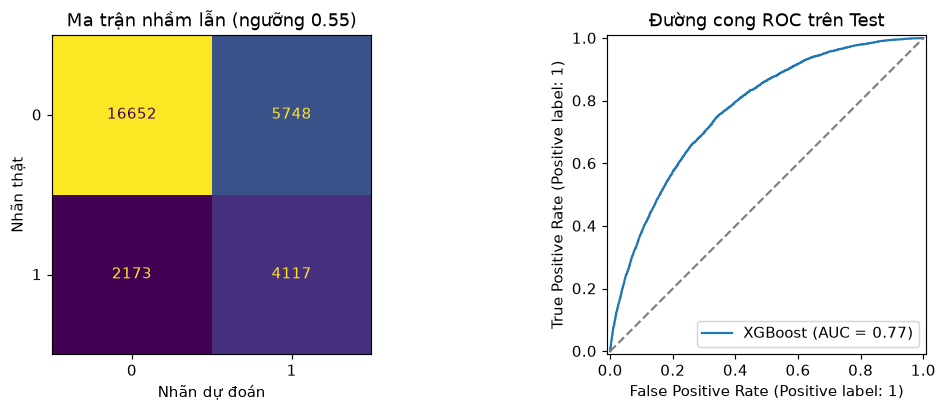

In [48]:
test_prob = best_model.predict_proba(X_te_model)[:, 1]
test_pred = (test_prob >= threshold).astype(int)
test_f1 = f1_score(y_te, test_pred, zero_division=0)
test_auc = roc_auc_score(y_te, test_prob)
display(pd.Series({
    'Ngưỡng': threshold, 'Accuracy': accuracy_score(y_te, test_pred),
    'Precision lớp 1': precision_score(y_te, test_pred, zero_division=0),
    'Recall lớp 1': recall_score(y_te, test_pred, zero_division=0),
    'F1 lớp 1': test_f1, 'ROC-AUC': test_auc,
}, name='Test').round(4).to_frame())

cm = confusion_matrix(y_te, test_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay(cm, display_labels=[0, 1]).plot(ax=axes[0], colorbar=False, values_format='d')
axes[0].set(title=f'Ma trận nhầm lẫn (ngưỡng {threshold:.2f})', xlabel='Nhãn dự đoán', ylabel='Nhãn thật')
RocCurveDisplay.from_predictions(y_te, test_prob, ax=axes[1], name='XGBoost')
axes[1].plot([0, 1], [0, 1], '--', color='gray')
axes[1].set_title('Đường cong ROC trên Test')
fig.tight_layout()
plt.show()

## 7.2. Phân tích lỗi

Dương tính giả (FP) là hồ sơ nhãn 0 bị dự đoán thành lớp 1. Âm tính giả (FN) là hồ sơ nhãn 1 bị bỏ sót. Nhóm báo cáo tỉ lệ lỗi trên từng lớp thật và đối chiếu theo nhóm tuổi để mô tả lỗi của mô hình trên Test.

**Kết quả.** Mô hình báo nhầm 5.748 hồ sơ lớp 0 (25,66%) và bỏ sót 2.173 hồ sơ lớp 1 (34,55%). Tỉ lệ báo nhầm cao nhất ở mã nhóm tuổi 12 (32,61%). Tỉ lệ bỏ sót cao nhất ở mã nhóm tuổi 13 (44,71%).

In [49]:
print(f'FP = {fp:,}/{tn + fp:,} hồ sơ lớp 0 ({fp / (tn + fp):.2%}).')
print(f'FN = {fn:,}/{tp + fn:,} hồ sơ lớp 1 ({fn / (tp + fn):.2%}).')

error_summary = []
for age, rows in X_te.groupby('Age').groups.items():
    a_tn, a_fp, a_fn, a_tp = confusion_matrix(y_te.loc[rows], test_pred[rows], labels=[0, 1]).ravel()
    error_summary.append((age, len(rows), a_fp, a_fn,
                          a_fp / (a_tn + a_fp) if a_tn + a_fp else np.nan,
                          a_fn / (a_tp + a_fn) if a_tp + a_fn else np.nan))
display(pd.DataFrame(error_summary, columns=[
    'Mã nhóm tuổi', 'Số hồ sơ', 'FP', 'FN', 'FP / số lớp 0', 'FN / số lớp 1',
]).round(4))

FP = 5,748/22,400 hồ sơ lớp 0 (25.66%).
FN = 2,173/6,290 hồ sơ lớp 1 (34.55%).


,Mã nhóm tuổi,Số hồ sơ,FP,FN,FP / số lớp 0,FN / số lớp 1
0,9,7451,1253,480,0.2085,0.3329
1,10,7310,1415,507,0.2493,0.3103
2,11,5533,1226,433,0.2940,0.3177
3,12,3930,977,343,0.3261,0.3672
4,13,4466,877,410,0.2471,0.4471


## 7.3. Feature Importance

Gain là mức giảm loss trung bình từ các lần chia dùng một biến. Nhóm đưa cả những biến cây chưa dùng vào bảng với gain bằng 0.

**Kết quả.** `HighBP` có gain cao nhất (1693,2655), tiếp theo lần lượt là `GenHlth` (580,9662), `BMI` (368,2549), `HighChol` (294,1069). Gain đo mức giảm loss và không thể hiện chiều đóng góp của biến hay quan hệ nhân quả.

,Gain trung bình
HighBP,1693.2655
GenHlth,580.9662
BMI,368.2549
HighChol,294.1069


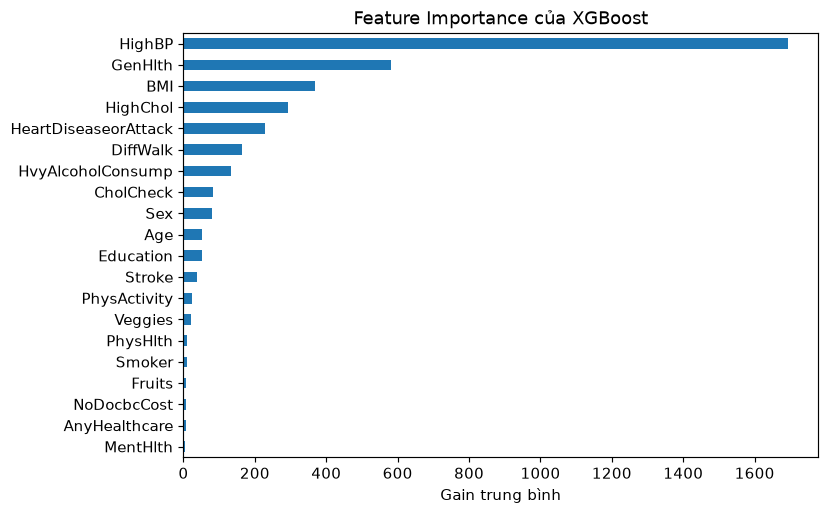

In [50]:
booster = best_model.get_booster()
gain = pd.Series(booster.get_score(importance_type='gain'), dtype=float)
gain = gain.reindex(selected_features, fill_value=0).sort_values()
display(gain.nlargest(4).round(4).rename('Gain trung bình').to_frame())
ax = gain.plot.barh(figsize=(8, 5), title='Feature Importance của XGBoost')
ax.set_xlabel('Gain trung bình')
plt.tight_layout()
plt.show()

## 7.4. SHAP

Nhóm dùng TreeSHAP tích hợp trong XGBoost trên tối đa 1.000 hồ sơ Test lấy mẫu với seed cố định. Trung bình |SHAP| xếp hạng mức đóng góp trên mẫu. Với từng ví dụ FP và FN, dấu dương đẩy điểm log-odds về lớp 1 và dấu âm kéo điểm về lớp 0. Nhóm minh họa lỗi có điểm dự đoán xa ngưỡng nhất trong mỗi loại lỗi.

**Kết quả.** Trên 1.000 hồ sơ Test lấy mẫu, `GenHlth` có trung bình |SHAP| cao nhất (0,4586 log-odds). Thứ hạng có thể khác gain vì gain đo mức giảm loss trung bình ở các lần chia, còn |SHAP| đo độ lớn đóng góp trung bình trên từng hồ sơ. Ở ca FP minh họa (điểm lớp 1 là 0,9345), `BMI` làm tăng log-odds lớp 1 mạnh nhất (SHAP 0,8437). Ở ca FN minh họa (điểm lớp 1 là 0,0187), `BMI` làm giảm log-odds lớp 1 mạnh nhất (SHAP -1,1758). Hai ca minh họa chỉ phản ánh hai hồ sơ được chọn.

FP: BMI, SHAP = +0.8437, điểm lớp 1 = 0.9345
FN: BMI, SHAP = -1.1758, điểm lớp 1 = 0.0187


,Trung bình |SHAP|
GenHlth,0.4586


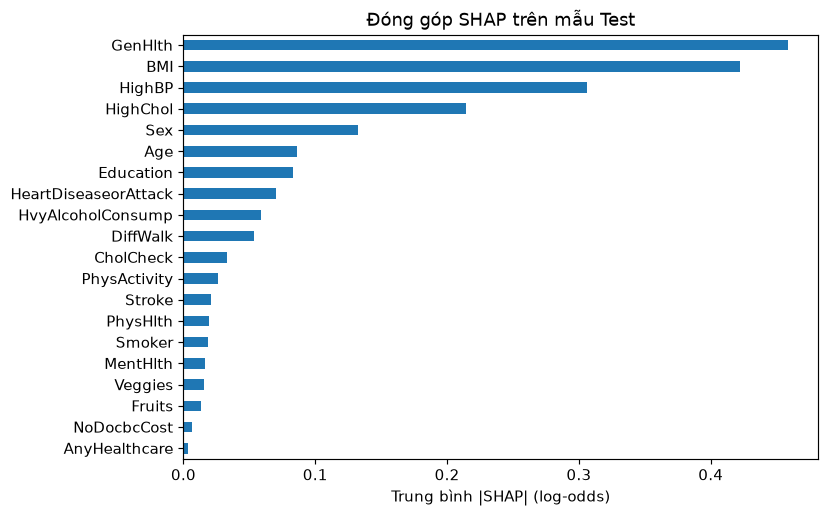

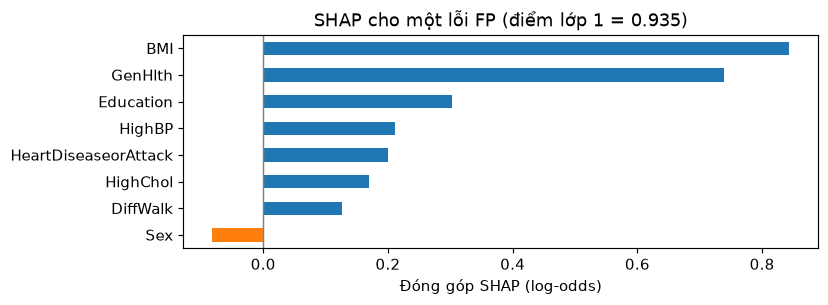

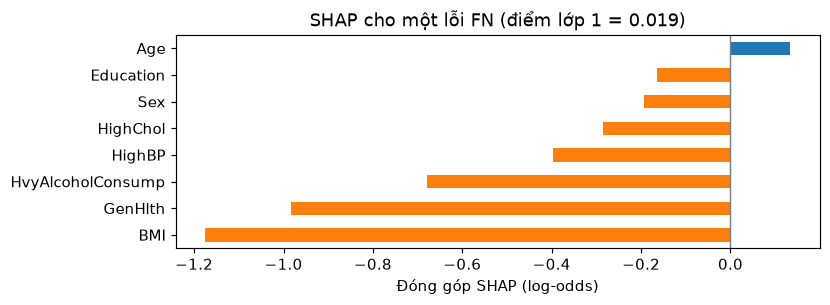

In [51]:
X_shap = X_te_model.sample(n=min(1000, len(X_te_model)), random_state=42)
shap_values = booster.predict(DMatrix(X_shap), pred_contribs=True)[:, :-1]
mean_abs_shap = pd.Series(np.abs(shap_values).mean(axis=0), index=selected_features).sort_values()
display(mean_abs_shap.nlargest(1).round(4).rename('Trung bình |SHAP|').to_frame())
ax = mean_abs_shap.plot.barh(figsize=(8, 5), title='Đóng góp SHAP trên mẫu Test')
ax.set_xlabel('Trung bình |SHAP| (log-odds)')
plt.tight_layout()
plt.show()

local_shap_examples = {}
for error_name, mask in [('FP', (y_te == 0) & (test_pred == 1)), ('FN', (y_te == 1) & (test_pred == 0))]:
    positions = np.flatnonzero(mask)
    if not positions.size:
        continue
    pos = positions[np.abs(test_prob[positions] - threshold).argmax()]
    contributions = booster.predict(DMatrix(X_te_model.iloc[[pos]]), pred_contribs=True)[0]
    local_shap = pd.Series(contributions[:-1], index=selected_features)
    main_feature = local_shap.abs().idxmax()
    local_shap_examples[error_name] = (main_feature, float(local_shap[main_feature]), float(test_prob[pos]))
    print(f'{error_name}: {main_feature}, SHAP = {local_shap[main_feature]:+.4f}, điểm lớp 1 = {test_prob[pos]:.4f}')
    top = local_shap.loc[local_shap.abs().nlargest(8).index].sort_values()
    ax = top.plot.barh(figsize=(8, 3), color=np.where(top >= 0, 'tab:blue', 'tab:orange'),
                      title=f'SHAP cho một lỗi {error_name} (điểm lớp 1 = {test_prob[pos]:.3f})')
    ax.axvline(0, color='gray', linewidth=1)
    ax.set_xlabel('Đóng góp SHAP (log-odds)')
    plt.tight_layout()
    plt.show()

# VIII. Kết luận và giới hạn

**Kết quả.** `baseline_20` đạt F1 CV 0,4956, còn `reduced16_plus4` đạt 0,4950. Phương án thay bốn biến gốc bằng bốn biến tương tác chưa cải thiện F1 CV. Nhóm dùng XGBoost làm mô hình cuối để dò siêu tham số, chọn ngưỡng và diễn giải dự đoán.

**Kết quả.** XGBoost dùng `baseline_20` và ngưỡng 0,55. Trên Test, F1 lớp 1 đạt 0,5097 và ROC-AUC đạt 0,7717. Tỉ lệ FP là 25,66% trên lớp 0 và tỉ lệ FN là 34,55% trên lớp 1. Nhóm từ 80 tuổi trở lên (mã 13) có tỉ lệ bỏ sót cao nhất (44,71%). Mã nhóm tuổi 10 có số FN cao nhất (507 hồ sơ).

Nhóm chọn bốn biến loại khỏi `reduced_16` bằng tương quan Pearson với nhãn trên toàn bộ dữ liệu sạch, gồm cả Test. Vì vậy, dữ liệu Test đã tham gia vào quyết định thiết kế bộ đặc trưng đem so sánh. Nhãn nghiên cứu là thông tin tự khai gộp tiền tiểu đường và tiểu đường ở người từ 60 tuổi trở lên.

## Hướng phát triển

- Xác thực ngoài trên dữ liệu của năm khác hoặc quần thể khác.
- Chọn biến trong phần fit của từng fold CV để giữ validation và Test ngoài bước chọn biến.
- Thử thêm biến lâm sàng hoặc hiệu chỉnh xác suất dự đoán.

In [52]:
print(f'XGBoost dùng {selected_name}, ngưỡng {threshold:.2f}.')
print(f'Test có F1 lớp 1 = {test_f1:.4f}, ROC-AUC = {test_auc:.4f}, {fp:,} báo nhầm và {fn:,} bỏ sót.')
print(f'Biến đứng đầu theo gain: {gain.idxmax()}. Theo trung bình |SHAP|: {mean_abs_shap.idxmax()}.')

XGBoost dùng baseline_20, ngưỡng 0.55.
Test có F1 lớp 1 = 0.5097, ROC-AUC = 0.7717, 5,748 báo nhầm và 2,173 bỏ sót.
Biến đứng đầu theo gain: HighBP. Theo trung bình |SHAP|: GenHlth.


## Tài liệu tham khảo

- [CDC BRFSS2015](https://www.cdc.gov/brfss/annual_data/annual_2015.html) và [BRFSS2015 Codebook](https://www.cdc.gov/brfss/annual_data/2015/pdf/CODEBOOK15_LLCP.pdf): nguồn dữ liệu, nội dung câu hỏi, mã phản hồi và nhánh câu hỏi.
- [Diabetes Health Indicators Dataset](https://www.kaggle.com/datasets/alexteboul/diabetes-health-indicators-dataset) và [notebook Alex Teboul](https://www.kaggle.com/code/alexteboul/diabetes-health-indicators-dataset-notebook): căn cứ kế thừa bộ biến đặc trưng và phần lớn quy trình xử lý ban đầu. Nhóm chọn người từ 60 tuổi trở lên trong báo cáo này, loại hồ sơ chỉ tiểu đường khi mang thai, và gộp tiền tiểu đường/tiểu đường thành lớp 1 theo định nghĩa nghiên cứu.
- Các nghiên cứu và tài liệu y tế chuyên ngành dịch tễ học. Nhóm xem xét khác biệt về quần thể, năm khảo sát, nhãn và cách đo khi sử dụng kết quả tham khảo.